> ## 🎤 강사 스크립트 · 이 강사용 노트북 사용법
>
> 이 노트북은 **학생용 `D29_LiveKit기초_실습.ipynb`의 모든 셀을 그대로 담고**, 사이사이에 **🎤 강사 스크립트 셀**을 끼워 넣은 것입니다. 수업 화면에는 학생용을, 강사 화면에는 이 노트북을 띄우세요.
>
> | 표시 | 뜻 |
> |---|---|
> | 🎯 | 이 블록에서 학생이 가져가야 할 한 가지 |
> | 🗣️ | 그대로 읽어도 되는 강사 멘트 |
> | 🍎 | 일상 비유 |
> | 🖥️ | 화면 시연 |
> | ❓ | 학생에게 던지는 질문 → 예상 답 |
> | 🆘 | 빈칸에서 막힌 학생에게 주는 힌트 |
> | ⚠️ | 자주 막히는 지점 · 오개념 · 오류 |
> | 🎧 | 반 전체가 같이 들을 소리 (스피커) |
> | ➡️ | 다음 블록으로 넘어가는 연결 멘트 |
>
> **오늘의 수업 방향**: 모델(Whisper · Qwen3 · Edge TTS · Silero)은 어제와 똑같고, **엮는 틀만 Pipecat → LiveKit Agents**로 바꿉니다. 핵심 메시지는 **"방(Room)에 출입증으로 들어간다 → 비서는 대본(Agent) + 진행자(AgentSession) → 귀 · 입 · 머리는 콘센트 모양(플러그인)만 맞추면 꽂힌다 → 작업자(Worker)는 방이 생기면 entrypoint를 부른다 → 같은 entrypoint가 가짜 방 · 진짜 방 · 브라우저에서 그대로 돈다"** 입니다. 칠판에 쓰는 것은 세 줄: **`출입증 = 누가 · 어느 방 · 무엇을 + Secret 서명`**, **`Agent = 무엇을, AgentSession = 어떻게`**, **`방 생김 → Job → entrypoint(ctx) → session.start(room=ctx.room)`**.
>
> > 🍎 **하루를 꿰는 비유: 콜센터 개설.** 출입증 발급(토큰) → 상담 매뉴얼(Agent) → 상담 시스템(AgentSession) → 장비 규격(플러그인) → 상담원 출근 · 배정(Worker · Job) → 개통(진짜 방 · 웹).
>
> > ⚠️ **Part 4-2(진짜 방)는 Colab에서 `get.livekit.io` 설치가 되어야 합니다.** 수업 전에 반드시 한 번 돌려 보세요. 학원 네트워크가 막혀 있으면 4-2는 강사 시연(집 · 테더링)으로 대체하고, 4-1 fake job으로 개념을 잡습니다.
>
> > 🔒 LiveKit Cloud 키(4-3)는 Colab 보안 비밀에만. 토큰 · 키를 화면 공유 · 노션 · 깃허브에 올리지 않게 다시 안내. 오늘 노트북의 `devkey / secret`은 **공개된 개발용 값**이라 괜찮다는 점도 분명히.
>
> > 💡 정답 · 예상 출력 · 힌트는 이 노트북에만 있습니다. **학생에게 배포하지 마세요.**

> ## 🎤 강사 스크립트 · 하루 시간표와 수업 전 점검
>
> #### 하루 시간표 (50분 수업 + 10분 쉬는 시간)
> | 시간 | 교시 | 내용 | 빈칸 | 애니메이션 | 슬라이드 |
> |---|---|---|---|---|---|
> | 0:00–0:50 | 1교시 | 도입, Part 0 설치 · Pipecat ↔ LiveKit 대응, Part 1 Room · Token | 1 · 2 | D29-1 · 2 · 3 | p.1 ~ 7 |
> | 1:00–1:50 | 2교시 | Part 2 Agent · AgentSession · LLM 플러그인 · `session.run` | 3 · 4 | D29-4 | p.8 ~ 11 |
> | 2:00–2:50 | 3교시 | Part 3 STT · TTS 플러그인 · 방 없이 통화 | 5 · 6 · 7 | D29-5 · 6 | p.12 ~ 15 |
> | 3:00–3:50 | 4교시 | Part 4 Worker · fake job · 진짜 방 · 웹 클라이언트, Part 5 정리 | 8 · 9 | D29-7 · 8 · 9 | p.16 ~ 20 |
>
> **진도가 밀릴 때 줄이는 순서** (빈칸 실습은 줄이지 않습니다)
> 1. 4-3 브라우저 통화는 강사 화면 시연만 (Cloud 키는 강사 계정)
> 2. Part 1 '참관인 토큰' ✏️ 생략
> 3. Part 3 48 kHz 받아쓰기 비교는 결과만 읽기
>
> #### 수업 전 점검 (전날)
> - [ ] 처음부터 끝까지 한 번 실행(T4, 로컬 Qwen이면 약 15분). Part 2 표, Part 3 통화 그림 · 지연 표, Part 4 fake job 그림 캡처
> - [ ] **4-2 진짜 방**: `LiveKit 서버: 실행 중 ✔`이 뜨고, 통화 그림의 위 줄(bot track)에 막대가 3개 생기는지. 안 되면 `livekit.log`를 열어 보기
> - [ ] **4-3 브라우저**: 강사 Cloud 프로젝트 키를 보안 비밀에 넣고 `RUN_BROWSER = True`로 위젯이 뜨는지, 🎤 허용 후 인사가 들리는지
> - [ ] **Edge TTS 소리 확인**: Part 0의 🎧 두 개가 사람 목소리인지(⚠️ 'Edge TTS 실패' 줄이 보이면 MMS로 돌아간 것)
> - [ ] [animation.html](https://imguru-mooc.github.io/AI_Voice/day29/animation.html) · [worksheet.html](https://imguru-mooc.github.io/AI_Voice/day29/worksheet.html) 탭 열기
>
> #### 오늘 학생들이 가장 많이 막히는 곳
> | 위치 | 증상 | 대응 |
> |---|---|---|
> | Part 0 | `AttributeError: 'function' object has no attribute 'STT'` | `stt`가 Whisper 함수 이름과 겹침 → 코드는 `lk_stt` · `lk_tts` · `lk_llm`을 씀. 학생이 `stt.STT`로 고쳐 쓴 경우 |
> | 빈칸 1 | `room_create`를 넣음 | 방을 '만드는' 관리자 권한. 들어가는 권한은 `room_join` |
> | 빈칸 4 | `generate_reply`를 넣음 | 동작은 하지만 `RunResult`가 아니라 `SpeechHandle`이 나와 `.expect`가 없음 → `run` |
> | 빈칸 5 | `recognize`를 넣음 | 무한 재귀(부모의 `recognize`가 다시 우리 메서드를 부름). 밑줄로 시작하는 `_recognize_impl` |
> | Part 3 | 셀이 60초 이상 | 로컬 Qwen 답이 길어짐(CPU). 키를 쓰거나 `max_new_tokens`를 40으로 |
> | Part 3 | 비서가 사용자 말 중간에 끊음 | 합성 목소리의 쉼 + 기본 턴 판단. D28 Part 2 복습 거리로 활용 |
> | 4-2 | `ConnectError ... Connection refused` | 서버가 안 떠 있음 → 위 셀 다시, `livekit.log` 확인 |
> | 4-3 | 위젯은 뜨는데 소리가 없음 | 브라우저 마이크 권한 · 스피커 음소거 · 회사 방화벽(UDP) 확인 |

# D29. LiveKit Agents 기초: Room · Agent Worker · Plugin 구조 · 웹 클라이언트 연결  —  🎤 강사용

**음성 AI 전문가 과정 (160h) | 6주차 M6 실시간 음성 파이프라인 (Pipecat · LiveKit) | 4시간**

## 학습 목표
1. LiveKit의 **Room · Participant · Track**과 SFU(미디어 중계 서버) 구조를 설명하고, 방에 들어가는 **출입증(Access Token, JWT)** 을 직접 만들어 열어 본다.
2. **Agent**(무엇을 할지: 지시문)와 **AgentSession**(어떻게 돌릴지: STT · LLM · TTS · VAD를 엮는 진행자)을 나누어 이해하고, 소리 없이 **글자로 먼저** 대화를 시험한다(`session.run`).
3. LiveKit **Plugin 구조**(정해진 부모 클래스 + 정해진 메서드 하나)를 따라 Whisper STT · Edge TTS · 로컬 Qwen LLM 플러그인을 직접 만든다.
4. 가짜 마이크 · 스피커(`AudioInput` · `AudioOutput`)를 붙여 **방 없이** 음성 대화를 돌리고, 턴마다 `e2e_latency`를 읽는다.
5. **Agent Worker**(`AgentServer` + `entrypoint`)가 방에 배정되는 흐름을 가짜 작업(fake job)으로 확인하고, 진짜 방(Colab 안 LiveKit 서버 · LiveKit Cloud 웹 클라이언트)에 연결한다.

## 오늘의 실습 흐름
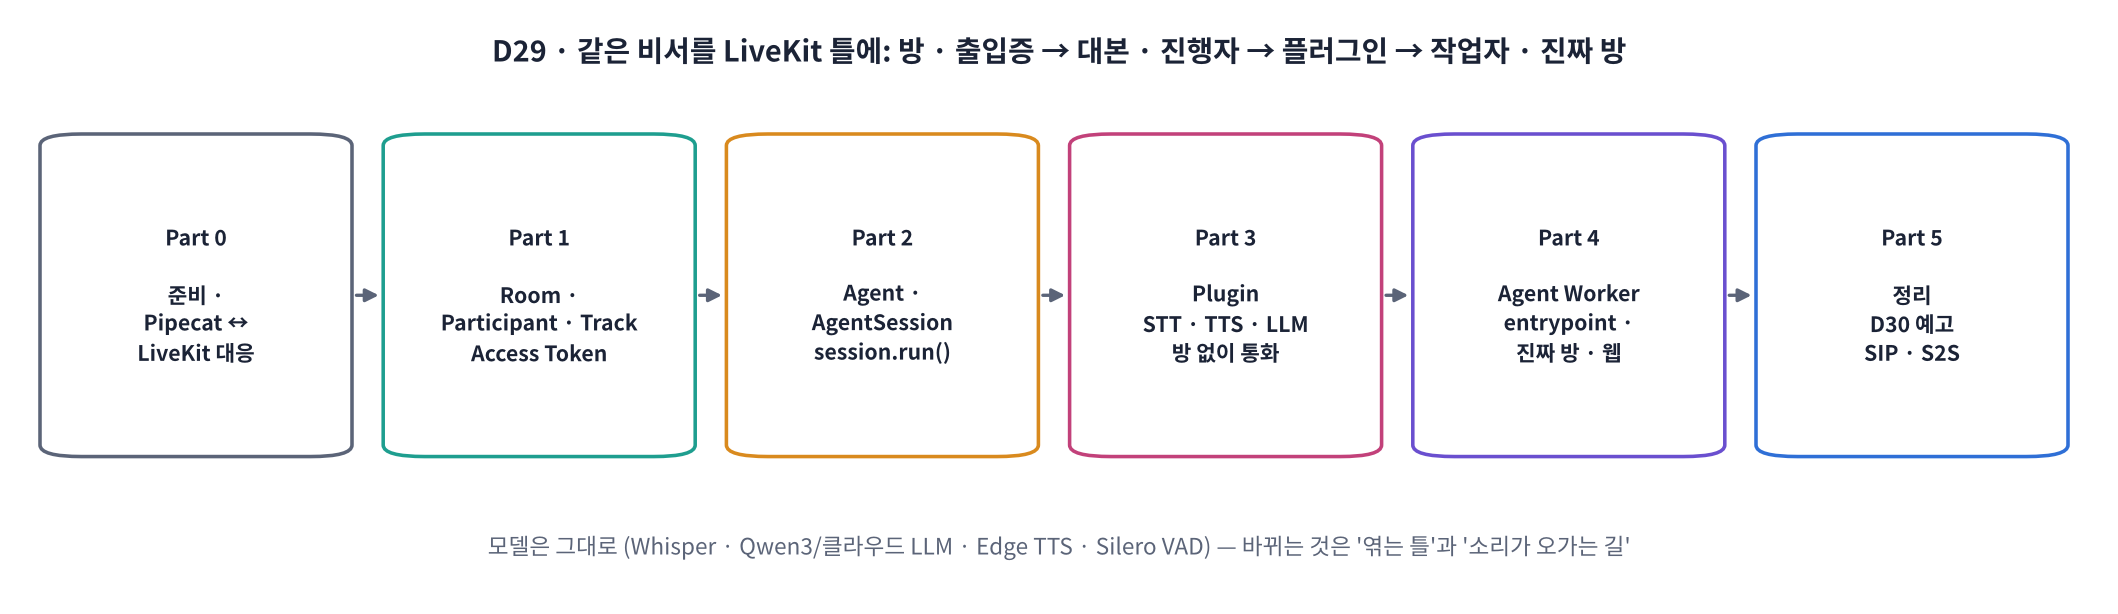

| 교시 | 내용 | 실습 | 산출물 |
|---|---|---|---|
| 1교시 | D28 복습(Pipecat ↔ LiveKit 대응), Room · Participant · Track, Access Token | Part 0 ~ 1, 워크시트 1교시 | 사용자 · 비서 토큰의 권한 비교표 |
| 2교시 | Agent · AgentSession, LLM 플러그인, 글자로 먼저 시험(`session.run`) | Part 2, 워크시트 2교시 | 3턴 대화 기록 · 턴별 LLM TTFT |
| 3교시 | Plugin 구조: STT · TTS 직접 만들기, 방 없이 음성 대화 | Part 3, 워크시트 3교시 | 플러그인 단독 시험 결과 · 통화 타임라인 · 지연 표 |
| 4교시 | Agent Worker(`AgentServer` · `entrypoint`), 진짜 방 · 웹 클라이언트 연결, 정리 | Part 4 ~ 5, 워크시트 4교시 | fake job 통화 기록 · 방 연결 결과 |

## 오늘의 수업 자료
| 자료 | 링크 | 언제 쓰나요 |
|---|---|---|
| 🎬 인터랙티브 애니메이션 | [animation.html](https://imguru-mooc.github.io/AI_Voice/day29/animation.html) | 방 구조(D29-2) · 토큰(D29-3) · 세션(D29-4 · 5) · 플러그인(D29-6) · 작업자(D29-7 · 8) |
| 📝 개념 워크시트 | [worksheet.html](https://imguru-mooc.github.io/AI_Voice/day29/worksheet.html) | 각 교시 끝에 해당 탭 10문항 (4교시 × 10문항), 오답 캡처 → 노션 |

## 이 노트북 사용법
- ▶️ 위에서부터 차례로 실행합니다. 모델 준비는 D27 · D28과 같고(Whisper · Edge TTS · Qwen3), **Pipecat 대신 LiveKit Agents**를 설치합니다.
- 🧩 **빈칸 실습** 셀은 `____`를 채우고 실행하면 ✅ 또는 ❌가 나옵니다. 🔑 **정답 및 해설 보기**를 누르면 정답이 펼쳐집니다.
- ✏️ 표시 셀은 값을 **직접 바꿔** 다시 실행해 보는 셀입니다.
- ⏳ Part 3 · 4의 음성 대화는 **실제 시간으로 흐르므로** 셀 하나에 20 ~ 40초가 걸립니다.

| 표시 | 뜻 |
|---|---|
| 💬 **쉽게 말하면** | 그 절의 내용을 한 문장으로 |
| 🍎 **비유** | 일상의 장면으로 바꿔 보기 |
| 👣 **한 단계씩** | 무슨 일이 어떤 순서로 일어나는지 |
| 📐 **핵심 식 하나** | 꼭 기억할 식 하나 |
| ❓ **생각해 보기** | 스스로 답해 보고 펼쳐서 확인 |
| 🎧 **들어 보기** | 소리로 확인 |

> ⚙️ **런타임 → T4 GPU**. 🔑 **LLM 키 (선택, D22 · D27과 같음)**: `ANTHROPIC_API_KEY` · `OPENAI_API_KEY` · `GEMINI_API_KEY` 중 하나가 있으면 그 LLM을, 없으면 **로컬 Qwen3**를 씁니다.
>
> 🌐 **LiveKit 키 (선택, Part 4-3에서만)**: `LIVEKIT_URL` · `LIVEKIT_API_KEY` · `LIVEKIT_API_SECRET`를 Colab 보안 비밀(🔑)에 넣으면 **브라우저 마이크로 비서와 통화**합니다. 없어도 Part 4-2까지는 **이 Colab 안의 LiveKit 서버**로 끝까지 진행됩니다. 키 · 토큰은 화면에 출력하지 않습니다.

> 🎬 **애니메이션 D29-1:** [오늘의 흐름](https://imguru-mooc.github.io/AI_Voice/day29/animation.html#flow) — Part 1~5 로드맵과 시간 계획

> ## 🎤 강사 스크립트 · 도입  ⏱️ 5분
>
> 🎯 **어제까지의 비서를 '서비스'로 띄우는 틀을 배운다. 모델은 그대로, 틀만 바뀐다.**
>
> 🗣️ "어제 비서는 우리 노트북 안에서, 우리가 만든 WebSocket으로만 통화했습니다. 진짜 서비스라면 사용자는 브라우저 · 앱 · 전화로 들어오고, 통화가 동시에 수십 개 생깁니다. 이걸 맡아 주는 것이 LiveKit입니다. 오늘은 같은 비서를 LiveKit 틀에 옮겨 담고, 마지막에는 브라우저 마이크로 통화합니다."
>
> 🖥️ [D29-1 오늘의 흐름](https://imguru-mooc.github.io/AI_Voice/day29/animation.html#flow)

## Part 0. 준비 (모델은 D27 · D28과 같음, 프레임워크만 LiveKit으로)

> 🛠️ `livekit-agents==1.8.10`을 고정해 설치합니다. `[silero,openai]`는 **플러그인**(Silero VAD · OpenAI 호환 LLM)을 함께 받는다는 뜻입니다. `livekit`(rtc, WebRTC 엔진)과 `livekit-api`(토큰 · 서버 API)도 같이 들어옵니다.

> ## 🎤 강사 스크립트 · Part 0  ⏱️ 8분
>
> 🖥️ 설치(1 ~ 2분) 동안 슬라이드 p.2 '오늘 답할 질문'.
>
> 🗣️ "`livekit-agents[silero,openai]`의 대괄호는 '플러그인도 같이'라는 뜻입니다. LiveKit은 회사별 STT · TTS · LLM을 전부 플러그인으로 나눠 놓았습니다. 오늘 우리는 기성 플러그인 2개(Silero VAD, OpenAI 호환 LLM)를 쓰고, 3개(Whisper STT, Edge TTS, Qwen LLM)를 직접 만듭니다."

In [ ]:
# 📦 설치: Colab 기본 패키지 버전은 그대로 고정하고 필요한 것만 추가 (런타임 재시작 불필요, 1 ~ 2분)
import importlib.metadata as md
KEEP = ["torch", "torchaudio", "torchvision", "torchcodec", "transformers", "tokenizers", "huggingface-hub", "datasets",
        "accelerate", "diffusers", "numpy", "scipy", "librosa", "numba", "safetensors", "requests",
        "click", "filelock", "rich", "typer", "pydantic", "httpx"]
pins = []
for p in KEEP:
    try:
        pins.append(f"{p}=={md.version(p)}")
    except md.PackageNotFoundError:
        pass
open("colab_constraints.txt", "w").write("\n".join(pins) + "\n")
print("고정한 버전:", ", ".join(pins))
!pip install -q -c colab_constraints.txt "livekit-agents[silero,openai]==1.8.10" "livekit-api>=1.2"
!pip install -q -c colab_constraints.txt uroman edge-tts
print("✅ 설치 완료")

In [ ]:
import os, re, sys, json, time, random, socket, asyncio, warnings, logging
from dataclasses import dataclass
import numpy as np
import pandas as pd
import librosa
import torch
import matplotlib.pyplot as plt
from IPython.display import Audio, display, Markdown
import importlib.metadata as md
warnings.filterwarnings("ignore")
logging.getLogger("transformers").setLevel(logging.ERROR)
for _name in ["livekit", "livekit.agents", "livekit.plugins"]:   # LiveKit은 logging으로 로그를 남김 → 오류만 보이게
    logging.getLogger(_name).setLevel(logging.ERROR)
from threading import Thread
from transformers import TextIteratorStreamer

from livekit import rtc, api                             # rtc: 방 · 참가자 · 트랙(WebRTC) · api: 토큰 · 서버 API
from livekit.agents import Agent, AgentSession, AgentServer, JobContext, JobExecutorType, utils, APIConnectOptions
from livekit.agents import stt as lk_stt, tts as lk_tts, llm as lk_llm   # 플러그인 부모 클래스 (stt · tts는 아래 Whisper · TTS 함수 이름과 겹쳐서 lk_를 붙임)
from livekit.agents.voice import io as lk_io             # 소리 입출력 자리 (AudioInput · AudioOutput)
from livekit.plugins import silero, openai as lk_openai  # 플러그인: Silero VAD · OpenAI 호환 LLM

GPU = torch.cuda.is_available()
DEVICE = "cuda" if GPU else "cpu"
SR = 16000
print(" · ".join(f"{p} {md.version(p)}" for p in ["livekit-agents", "livekit", "livekit-api", "torch", "transformers"]))
print("GPU:", torch.cuda.get_device_name(0) if GPU else "없음 (CPU로도 가능)")

def check(cond, hint="빈칸을 다시 확인하세요."):
    print("✅ 정답입니다! 🎉" if cond else f"❌ {hint}")

def set_seed(s=0):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if GPU: torch.cuda.manual_seed_all(s)

def to_np(y):
    y = y.detach().cpu().numpy() if torch.is_tensor(y) else np.asarray(y)
    return y.reshape(-1).astype(np.float32)

def play(y, sr=SR, label=""):
    y = to_np(y)
    print(f"🎧 {label}  ({len(y) / sr:.2f}초)")
    if len(y): display(Audio(y, rate=sr))
    else: print("   (소리 없음: 위의 경고 · 오류를 확인하세요)")

def silence(sec, sr=SR):
    return np.zeros(int(sec * sr), np.float32)

# D16 정규화 (숫자 → 읽는 말): TTS 바로 앞에서 씀
DIGITS = "영일이삼사오육칠팔구"
def sino(n):
    if n == 0: return "영"
    out = ""
    for big in ["", "만", "억", "조"]:
        chunk, n = n % 10000, n // 10000; s = ""
        for i, unit in enumerate(["", "십", "백", "천"]):
            d, chunk = chunk % 10, chunk // 10
            if d: s = ("" if d == 1 and i > 0 else DIGITS[d]) + unit + s
        if s: out = ("" if s == "일" and big == "만" else s) + big + out
        if n == 0: break
    return out
ONES = ["", "한", "두", "세", "네", "다섯", "여섯", "일곱", "여덟", "아홉"]
TENS = ["", "열", "스물", "서른", "마흔", "쉰", "예순", "일흔", "여든", "아흔"]
def native(n): return sino(n) if not 0 < n < 100 else ("스무" if n == 20 else TENS[n // 10] + ONES[n % 10])
NATIVE_COUNTERS = ["시간", "개", "명", "살", "마리", "권", "잔", "병", "장", "달", "시"]
def normalize_ko(t):
    t = re.sub(r"(\d+)\s*(" + "|".join(NATIVE_COUNTERS) + ")", lambda m: native(int(m.group(1))) + " " + m.group(2), t)
    t = re.sub(r"(\d+)\s*%", lambda m: sino(int(m.group(1))) + " 퍼센트", t)
    t = re.sub(r"\d+", lambda m: sino(int(m.group(0))), t)
    return re.sub(r"\s+", " ", t).strip()
print(normalize_ko("오후 2시에 3명, 주차는 2시간 무료, 할인 10%"))

In [ ]:
# 🔊 모델 준비 (D27 · D28과 같음): 받아쓰기 Whisper · 합성 Edge TTS (예비 MMS-TTS) + 오늘의 사용자 말 두 마디
from transformers import AutoTokenizer, VitsModel, WhisperProcessor, WhisperForConditionalGeneration
import uroman as ur
tts_tok = AutoTokenizer.from_pretrained("facebook/mms-tts-kor")
tts_model = VitsModel.from_pretrained("facebook/mms-tts-kor").to(DEVICE).eval()
U = ur.Uroman()
ASR_NAME = "openai/whisper-small" if GPU else "openai/whisper-tiny"
asr_proc = WhisperProcessor.from_pretrained(ASR_NAME)
asr = WhisperForConditionalGeneration.from_pretrained(ASR_NAME).to(DEVICE).eval()

import functools, tempfile
VOICE_BOT, VOICE_USER = "ko-KR-SunHiNeural", "ko-KR-InJoonNeural"   # ✏️ Edge 신경망 음성: 비서 · 사용자 대역
TTS_ENGINE = "edge"                                      # 인터넷 · 서비스 문제로 실패하면 자동으로 "mms"(예비)

@functools.lru_cache(maxsize=512)                        # 같은 문장은 다시 요청하지 않음
def _edge_tts(text, voice):
    import edge_tts
    fd, path = tempfile.mkstemp(suffix=".mp3"); os.close(fd)
    try:
        edge_tts.Communicate(text, voice).save_sync(path)
        return librosa.load(path, sr=SR)[0].astype(np.float32)   # MP3 24 kHz → 16 kHz
    finally:
        os.remove(path)

def _mms_tts(text, seed=0):                              # 예비: MMS-TTS 한국어 VITS (D16)
    set_seed(seed)
    enc = tts_tok(U.romanize_string(text), return_tensors="pt").to(DEVICE)
    with torch.no_grad():
        return to_np(tts_model(**enc).waveform[0])

def tts(text, seed=0, voice=None):                       # 글자 → 16 kHz 소리: Edge 신경망 음성, 실패하면 MMS-TTS
    global TTS_ENGINE
    if TTS_ENGINE == "edge":
        try:
            return _edge_tts(text, voice or VOICE_BOT).copy()
        except Exception as e:
            print(f"⚠️ Edge TTS 실패 → MMS-TTS로 전환 ({type(e).__name__}: {str(e)[:80]})"); TTS_ENGINE = "mms"
    return _mms_tts(text, seed)

def user_tts(text, seed=0):                              # 사용자 대역 목소리: 비서와 다른 목소리 (MMS 예비일 때는 3반음 낮춰 구분)
    y = tts(text, seed=seed, voice=VOICE_USER)
    return librosa.effects.pitch_shift(y, sr=SR, n_steps=-3) if TTS_ENGINE == "mms" else y

def stt(y):                                              # 16 kHz 소리 → 글자
    feats = asr_proc.feature_extractor(to_np(y), sampling_rate=SR, return_tensors="pt").input_features.to(DEVICE)
    with torch.no_grad():
        ids = asr.generate(input_features=feats, language="korean", task="transcribe", max_new_tokens=96)
    return asr_proc.batch_decode(ids, skip_special_tokens=True)[0].strip()

def make_voice(text):                                    # 앞 0.5초 · 뒤 1초 조용함을 붙인 '사용자 말'
    y = np.concatenate([silence(0.5), user_tts(text), silence(1.0)]).astype(np.float32)
    return y / (np.abs(y).max() + 1e-9) * 0.8

SAY1 = "안녕하세요, 다음 주 수요일 오후 두 시에 스케일링 예약하고 싶어요."   # 오늘의 사용자 말 두 마디 (D27 · D28과 같은 상황)
SAY2 = "네, 이름은 김민준이에요."
VOICE1, VOICE2 = make_voice(SAY1), make_voice(SAY2)
GREET = "안녕하세요, 한빛치과 예약 도우미 하나입니다. 무엇을 도와드릴까요?"
play(VOICE1, SR, "사용자 말 1"); play(VOICE2, SR, "사용자 말 2")
print("받아쓰기 확인:", stt(VOICE1), "/", stt(VOICE2))

> ## 🎤 강사 스크립트 · 오늘의 사용자 말  ⏱️ 3분
>
> 🎧 두 마디: 예약 요청 · 이름. D27과 같은 상황이라 어제 결과와 비교할 수 있습니다.
>
> ✅ 받아쓰기 두 줄이 대체로 맞으면 OK.

In [ ]:
# 🔑 LLM 고르기 (D22와 같음): 키가 있으면 클라우드, 없으면 로컬 Qwen3
def secret(name):
    try:
        from google.colab import userdata
        v = userdata.get(name)
        if v: return v
    except Exception:
        pass
    return os.environ.get(name) or None

MODELS = {"claude": "claude-haiku-5-5",                 # ✏️ 모델 이름은 수업 당일 각 회사 문서에서 확인
          "openai": "gpt-6-luna",
          "gemini": "gemini-3.5-flash-lite",
          "local": "Qwen/Qwen3-1.7B" if GPU else "Qwen/Qwen3-0.6B"}
KEYS = {"claude": "ANTHROPIC_API_KEY", "openai": "OPENAI_API_KEY", "gemini": "GEMINI_API_KEY"}
BASE_URLS = {"claude": "https://api.anthropic.com/v1/",                      # 세 회사 모두 'OpenAI 호환' 주소를 제공
             "openai": None,
             "gemini": "https://generativelanguage.googleapis.com/v1beta/openai/"}
AVAILABLE = [p for p in ["claude", "openai", "gemini"] if secret(KEYS[p])] + ["local"]
PROVIDER = AVAILABLE[0]                                  # ✏️ 바꿔 보기: "local" 등

if PROVIDER == "local":
    from transformers import AutoModelForCausalLM
    tok = AutoTokenizer.from_pretrained(MODELS["local"])
    llm_model = AutoModelForCausalLM.from_pretrained(MODELS["local"], dtype=torch.float16 if GPU else torch.float32).to(DEVICE).eval()

SYSTEM = ("당신은 한빛치과의 전화 예약 도우미입니다. 음성으로 답하므로 한두 문장의 짧은 구어체로 말하고, "
          "목록 · 기호 · 이모지는 쓰지 않습니다. 예약에는 날짜 · 시간 · 진료 · 이름이 필요하며, 빠진 것이 있으면 하나씩 물어봅니다.")
print("쓸 수 있는 LLM:", AVAILABLE, "→ 오늘 쓸 LLM:", PROVIDER, MODELS[PROVIDER])

> ## 🎤 강사 스크립트 · LLM 고르기  ⏱️ 1분
>
> D22 · D27과 같음. 키가 없으면 local. LiveKit 키는 4-3에서만 쓴다고 미리 말해 두기.

### 🧭 D28 복습: Pipecat에서 LiveKit으로 — 같은 일, 다른 이름

어제까지 Pipecat으로 만든 비서와 **하는 일은 똑같습니다**. 귀(STT) · 머리(LLM) · 입(TTS) · 언제 말이 끝났나(VAD · 턴 판단)를 엮어 돌립니다. 달라지는 것은 **누가 엮어 주느냐**와 **소리가 어디로 오가느냐**입니다.

| 하는 일 | Pipecat (D27 · D28) | LiveKit Agents (오늘) |
|---|---|---|
| 전체를 엮어 돌리는 것 | `Pipeline` + `PipelineWorker` (작업자를 **직접 줄 세움**) | `AgentSession` (**진행자**가 알아서 엮음) |
| 비서의 성격 · 지시문 | `LLMContext`의 system 메시지 | `Agent(instructions=...)` |
| STT · LLM · TTS를 내 것으로 | `SegmentedSTTService.run_stt` · `TTSService.run_tts` | `stt.STT._recognize_impl` · `tts.ChunkedStream._run` · `llm.LLMStream._run` |
| 소리가 오가는 곳 | `Transport` (WebSocket · WebRTC · 전화) | **Room** (LiveKit 서버의 방 = WebRTC) |
| 서비스로 띄우기 | 직접 서버 프로그램 작성 | **Agent Worker**: 방이 생기면 서버가 일감(Job)을 보내 줌 |
| 지연 재기 | `MetricsFrame` · `UserBotLatencyObserver` | 메시지마다 붙는 `metrics` (`e2e_latency` 등) |

> 💬 **쉽게 말하면**: Pipecat은 '부품을 내가 줄 세우는 조립 키트', LiveKit Agents는 '진행자(세션)가 정해진 자리(STT · LLM · TTS 칸)에 부품을 꽂아 돌리는 틀'입니다.

**❓ 생각해 보기**: D28에서 'Smart Turn · 끼어들기 · Mute'를 위해 바꾼 손잡이는 Pipecat에서는 어디에 있었나요? LiveKit에서는 어디에 있을까요?

<details>
<summary>답 보기</summary>

Pipecat에서는 사용자 턴 전략(`UserTurnStrategies`의 start · stop)과 Mute 전략으로 **작업자 사이에** 끼워 넣었습니다. LiveKit에서는 이런 손잡이가 **`AgentSession`의 설정**(`turn_handling` · `vad` 등)에 모여 있습니다. 즉 '진행자에게 규칙을 알려 주는' 방식입니다. 오늘은 기본값으로 돌리고, 심화 손잡이는 D30에서 다룹니다.

</details>

> ## 🎤 강사 스크립트 · Pipecat ↔ LiveKit 대응표  ⏱️ 6분
>
> 🎯 **하는 일은 같고, '누가 엮느냐'와 '소리가 오가는 곳'이 다르다.**
>
> 🗣️ "표를 왼쪽에서 오른쪽으로 읽으세요. Pipecat에서는 작업자를 `Pipeline([...])`에 우리가 직접 줄 세웠습니다. LiveKit에서는 `AgentSession(stt=, llm=, tts=, vad=)`처럼 **칸만 채우면** 진행자가 순서를 압니다. 편한 대신, 칸 사이에 우리만의 작업자를 끼우려면 'node'를 바꿔 끼워야 합니다(D30에서 잠깐)."
>
> ❓ "어느 쪽이 더 좋나요?" → 정답 없음. Pipecat = 자유도 · 전송 방식이 다양, LiveKit = WebRTC 방 · 작업자 배정 · 확장이 갖춰짐. **둘 다 쓸 줄 알면** 프로젝트에 맞게 고름.
>
> 🖥️ 슬라이드 p.3 (대응표 그림)

## Part 1. LiveKit의 방: Room · Participant · Track, 그리고 출입증(Token)  ·  1교시

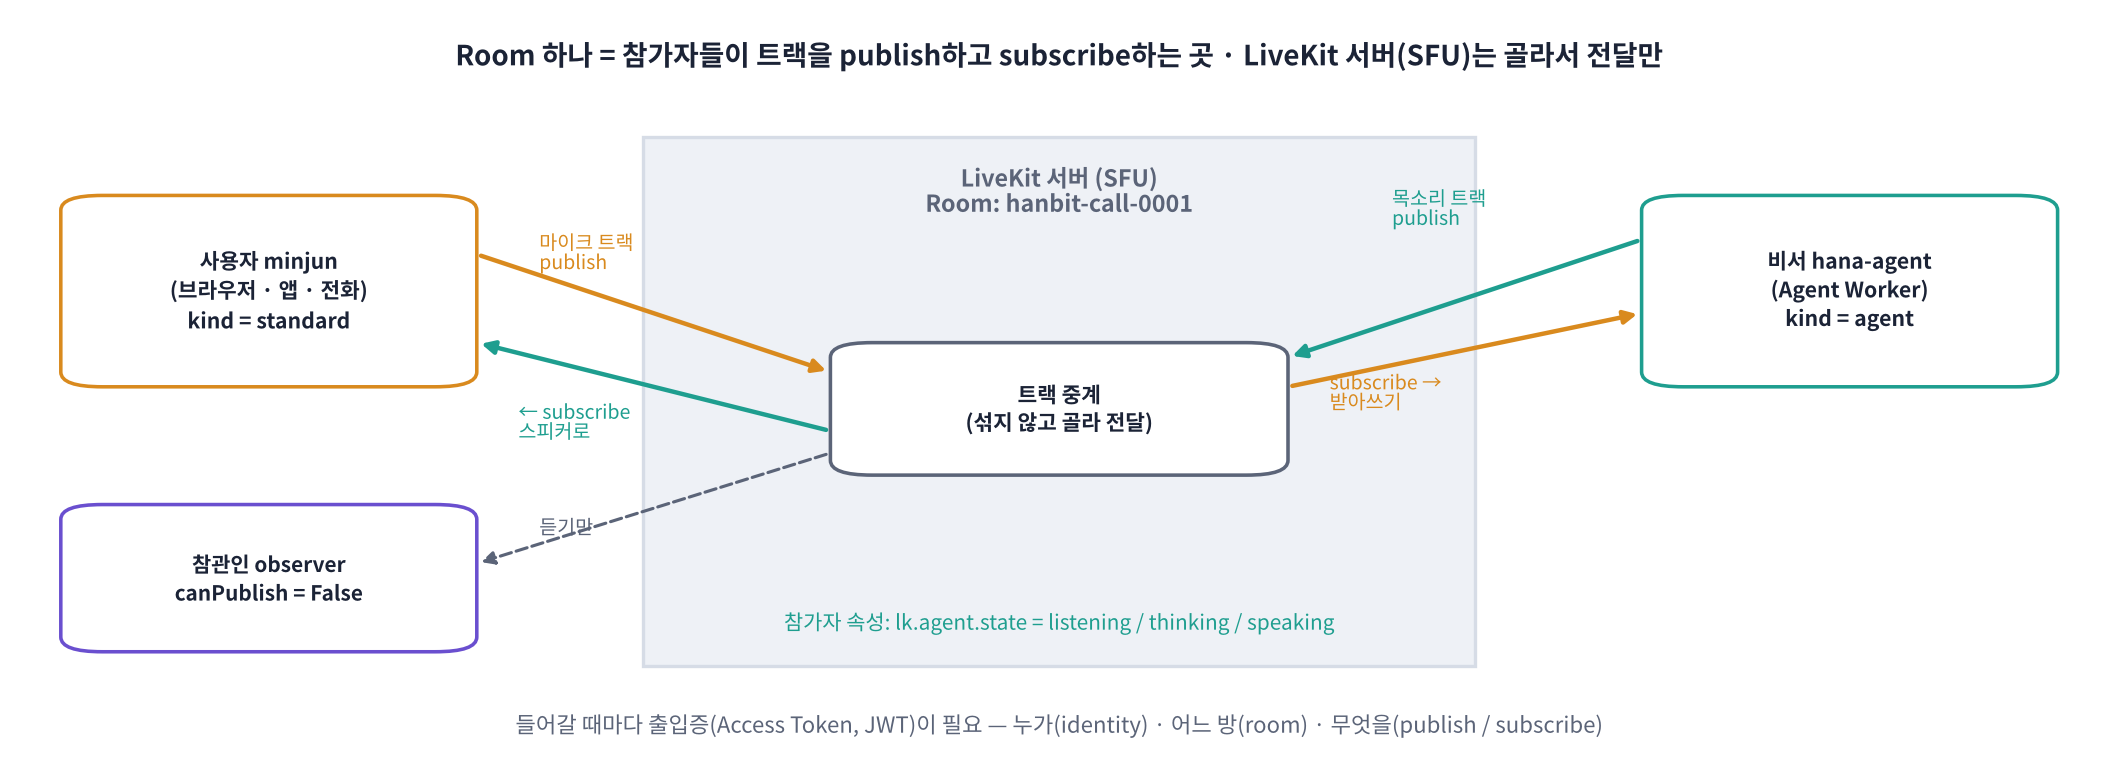

- **Room(방)**: LiveKit 서버 안의 대화방 하나. 방 이름으로 구분합니다 (예: `hanbit-call-0001`).
- **Participant(참가자)**: 방에 들어온 사람 **또는 프로그램**. 브라우저의 사용자도, 우리 AI 비서(Agent)도 똑같이 참가자입니다.
- **Track(트랙)**: 참가자가 내보내는(publish) 소리 · 영상 줄기. 다른 참가자는 그 트랙을 **구독(subscribe)** 해서 받습니다.
- **SFU**(Selective Forwarding Unit): LiveKit 서버가 하는 일. 소리를 섞거나 고치지 않고 **필요한 참가자에게 골라서 전달**만 합니다.

> 🍎 **비유**: 화상회의 방을 떠올려 보세요. 회의실(Room)에 사람(Participant)이 들어오고, 각자 마이크(Track)를 켭니다. 회의 서버는 내 마이크 소리를 다른 사람에게 **나눠 줄 뿐**입니다. 오늘의 AI 비서는 이 회의에 **참석자 한 명으로 들어오는 프로그램**입니다.
>
> 💬 **쉽게 말하면**: 사용자와 비서가 **같은 방에 들어가 서로의 마이크 트랙을 듣는 것**이 LiveKit 통화입니다.

> 🎬 **애니메이션 D29-2:** [방 · 참가자 · 트랙](https://imguru-mooc.github.io/AI_Voice/day29/animation.html#room) — 사용자 · 비서가 들어오고 트랙을 publish · subscribe하는 과정

### 1-1. 출입증 만들기: Access Token (JWT)

방에 들어가려면 **출입증**이 필요합니다. LiveKit의 출입증은 **JWT**(JSON Web Token)라는 글자 한 줄입니다. 서버 운영자만 가진 **API Secret**으로 서명하므로, 받은 사람이 내용을 바꾸면 서버가 바로 알아챕니다.

👣 **한 단계씩**
1. `api.AccessToken(API_KEY, API_SECRET)`: 누가 발급하는지(서버의 키 쌍)
2. `.with_identity("...")`: 이 출입증을 쓸 **참가자 이름**
3. `.with_grants(api.VideoGrants(...))`: **권한** — 어느 방에(`room`) 들어갈 수 있는지(`room_join`), 말할 수 있는지(`can_publish`), 들을 수 있는지(`can_subscribe`)
4. `.with_ttl(...)`: 유효 시간
5. `.to_jwt()`: 서명해서 **글자 한 줄**로 만들기

> 🔒 지금은 키가 없어도 됩니다. Part 4-2에서 띄울 **개발용 LiveKit 서버**(`livekit-server --dev`)의 공개된 개발용 키(`devkey` / `secret`)로 연습합니다. 실제 서비스 키는 절대 노트북 · 깃허브 · 노션에 붙여 넣지 않습니다.

> ## 🎤 강사 스크립트 · Part 1 Room · Participant · Track  ⏱️ 8분
>
> 🎯 **비서도 '참가자 한 명'이다.**
>
> 🖥️ [D29-2 방 · 참가자 · 트랙](https://imguru-mooc.github.io/AI_Voice/day29/animation.html#room): ▶ 누르면 사용자 입장 → 마이크 트랙 publish → 비서 입장 → subscribe → 비서 목소리 publish 순서로 보임.
>
> 🗣️ "줌 회의를 떠올리세요. 회의 서버는 여러분 목소리를 섞지 않고 필요한 사람에게 나눠 줄 뿐입니다. 그래서 SFU(Selective Forwarding Unit)라고 부릅니다. 우리 AI 비서는 이 회의에 **참석자로 들어오는 프로그램**입니다. 서버 입장에서는 사람과 비서가 거의 같습니다. 다른 점은 출입증에 적힌 `kind = agent` 하나뿐입니다."
>
> ⚠️ 오개념: "LiveKit 서버가 받아쓰기를 해 준다" → 아님. 서버는 소리를 **중계만** 하고, 받아쓰기 · 답 · 합성은 전부 작업자(우리 코드)에서.

In [ ]:
# 🧩 빈칸 실습 1 · 2: 출입증(Access Token) 만들기
import datetime
DEV_URL, DEV_KEY, DEV_SECRET = "ws://127.0.0.1:7880", "devkey", "secret"   # 개발용 서버(--dev)의 공개 키: 연습 전용
ROOM = "hanbit-call-0001"

def make_token(identity, room=ROOM, key=DEV_KEY, secret_=DEV_SECRET, agent=False, minutes=10, can_publish=True):
    grants = api.VideoGrants(____=True, room=room,                      # 빈칸 1: 방에 '들어갈' 수 있는 권한
                             can_publish=can_publish, can_subscribe=True, agent=agent or None)
    t = (api.AccessToken(key, secret_)
         .with_identity(identity)
         .with_name("하나(AI 비서)" if agent else identity)
         .with_grants(grants)
         .with_ttl(datetime.timedelta(minutes=minutes)))
    if agent:
        t = t.with_kind("agent")                                         # 참가자 종류: 사람(standard) / 비서(agent)
    return t.____()                                                      # 빈칸 2: 서명해서 글자 한 줄(JWT)로

USER_TOKEN = make_token("minjun")
print("토큰 길이:", len(USER_TOKEN), "글자 · 점(.)으로 나뉜 조각:", USER_TOKEN.count(".") + 1, "개")
print("앞부분만:", USER_TOKEN[:20] + "…")                                 # 토큰 전체는 출력하지 않는 습관
check(USER_TOKEN.count(".") == 2 and len(USER_TOKEN) > 100, "VideoGrants의 방 입장 권한 이름과, 토큰을 글자로 만드는 메서드를 확인하세요.")

> ## 🎤 강사 스크립트 · 빈칸 1 · 2  ⏱️ 6분
>
> 🆘 빈칸 1: "방에 **'들어가는'** 권한. room + join". 빈칸 2: "JWT로 바꾸는 메서드 = to + jwt".
>
> ✅ `토큰 길이: 300 ~ 400 글자 · 조각 3개`, `앞부분만: eyJhbGciOiJIUzI1NiIs…` (모든 JWT가 eyJ로 시작 = `{"`를 base64로 바꾼 것).
>
> ⚠️ `InsecureKeyLengthWarning`이 보일 수 있음: 개발용 secret이 짧아서. 실서비스 secret은 32자 이상.

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
grants = api.VideoGrants(room_join=True, room=room, ...)
...
return t.to_jwt()
```

**해설**: `room_join=True`가 있어야 `room`에 적힌 방에 **들어갈** 수 있습니다(방을 만들거나 지우는 `room_create` · `room_admin`과는 다른 권한). `to_jwt()`는 지금까지 적은 내용(누구 · 어느 방 · 무엇을 할 수 있나 · 언제까지)을 API Secret으로 **서명**해 `머리.내용.서명` 세 조각의 글자 한 줄로 만듭니다.

</details>

### 1-2. 출입증 열어 보기: 누구나 읽을 수 있지만, 아무나 고칠 수는 없다

JWT의 세 조각 중 앞의 두 조각(머리 · 내용)은 **암호화가 아니라 base64 글자 바꿈**일 뿐이라 누구나 읽을 수 있습니다. 대신 세 번째 조각(**서명**)은 Secret이 있어야 만들 수 있어서, 내용을 한 글자라도 고치면 서버가 거절합니다.

📐 **핵심 식 하나**: `서명 = HMAC-SHA256( API Secret,  머리 + "." + 내용 )`

> 🎬 **애니메이션 D29-3:** [토큰의 세 조각](https://imguru-mooc.github.io/AI_Voice/day29/animation.html#token) — 머리 · 내용 · 서명, 내용을 고치면 왜 거절되는지

> ## 🎤 강사 스크립트 · 토큰의 세 조각  ⏱️ 4분
>
> 🖥️ [D29-3 토큰의 세 조각](https://imguru-mooc.github.io/AI_Voice/day29/animation.html#token): 내용(payload)의 글자를 하나 바꾸면 서명이 빨갛게 '불일치'로 바뀌는 것 보여 주기.
>
> 🗣️ "JWT는 **비밀 편지가 아니라 도장 찍은 공문**입니다. 누구나 읽을 수 있지만, 도장(서명)은 Secret을 가진 사람만 찍을 수 있습니다."

In [ ]:
# 🔍 토큰 열어 보기 + 진짜인지 확인하기
import base64
def peek(jwt):                                           # 머리 · 내용 조각을 base64로 풀어 보기 (서명은 확인하지 않음)
    def dec(part): return json.loads(base64.urlsafe_b64decode(part + "=" * (-len(part) % 4)))
    head, body, sig = jwt.split(".")
    return dec(head), dec(body)

head, body = peek(USER_TOKEN)
print("머리(header):", head)
print("내용(payload):", json.dumps({k: body[k] for k in ["sub", "name", "video"] if k in body}, ensure_ascii=False))
print("유효 시간:", (body["exp"] - body["nbf"]) // 60, "분")

verifier = api.TokenVerifier(DEV_KEY, DEV_SECRET)        # 서버가 하는 일: Secret으로 서명을 다시 계산해 비교
print("\n① 원래 토큰  →", "통과 ✔" if verifier.verify(USER_TOKEN).identity == "minjun" else "?")

h, b, s = USER_TOKEN.split(".")                          # 나쁜 사용자가 내용을 고쳐 '관리자 권한'을 넣어 본다면?
body2 = dict(body); body2["video"] = dict(body["video"], roomAdmin=True)
b2 = base64.urlsafe_b64encode(json.dumps(body2).encode()).decode().rstrip("=")
for name, tok_ in [("② 내용을 고친 토큰", f"{h}.{b2}.{s}"), ("③ 다른 Secret으로 확인", USER_TOKEN)]:
    try:
        (api.TokenVerifier(DEV_KEY, "other-secret-xxxxxxxxxxxxxxxxxxxxxxxx") if name.startswith("③") else verifier).verify(tok_)
        print(name, "→ 통과 (?)")
    except Exception as e:
        print(name, "→ 거절 ✘", type(e).__name__)

> ## 🎤 강사 스크립트 · 토큰 열어 보기  ⏱️ 4분
>
> ✅ ① 통과 ✔ · ② 거절 ✘ InvalidSignatureError · ③ 거절 ✘ InvalidSignatureError.
>
> ❓ "그럼 토큰을 훔치면?" → 유효 시간 안에는 그 권한 그대로 쓸 수 있음. 그래서 ttl을 짧게(Colab 위젯은 1분), 방 이름을 정해서(room) 발급.

In [ ]:
# ✏️ 사용자 출입증 vs 비서 출입증: 무엇이 다를까?
AGENT_TOKEN = make_token("hana-agent", agent=True)
VIEWER_TOKEN = make_token("observer", can_publish=False)              # ✏️ 듣기만 하는 참관인 (예: 상담 품질 관리자)
rows = []
for who, t in [("사용자 minjun", USER_TOKEN), ("비서 hana-agent", AGENT_TOKEN), ("참관인 observer", VIEWER_TOKEN)]:
    _, b = peek(t); v = b["video"]
    rows.append({"참가자": who, "kind": b.get("kind", "standard"), "방": v.get("room"), "입장 roomJoin": v.get("roomJoin"),
                 "말하기 canPublish": v.get("canPublish"), "듣기 canSubscribe": v.get("canSubscribe"), "비서 agent": v.get("agent", False)})
display(pd.DataFrame(rows))

> ## 🎤 강사 스크립트 · 권한 비교표  ⏱️ 3분
>
> ✅ 비서만 `kind = agent` · `agent = True`, 참관인만 `canPublish = False`.
>
> ❓ "상담 품질 관리자가 통화를 몰래 듣는다면 무엇을 더 줘야 할까?" → `hidden=True`(다른 참가자 목록에 안 보임). 법 · 고지 문제는 별도로 반드시 검토.

**❓ 생각해 보기**: 출입증은 **누가, 어디서** 만들어야 할까요? 브라우저(웹 페이지) 안의 JavaScript가 직접 만들면 무엇이 문제일까요?

<details>
<summary>답 보기</summary>

출입증을 만들려면 **API Secret**이 필요합니다. 브라우저 코드에 Secret을 넣으면 누구나 개발자 도구로 꺼내 볼 수 있고, 그러면 아무 방에나 관리자 권한으로 들어가는 출입증을 마음대로 만들 수 있습니다. 그래서 출입증은 항상 **우리 서버(백엔드)** 가 만들고, 브라우저는 로그인 확인 뒤 **완성된 토큰만** 받아 갑니다. 유효 시간(`ttl`)을 짧게 주는 것도 같은 이유입니다(Part 4-3의 Colab 위젯은 1분짜리 토큰을 씁니다).

</details>

> 📝 **워크시트 1교시** 10문항을 풀어 보세요.

> ## 🎤 강사 스크립트 · 토론 + 워크시트 1교시  ⏱️ 5분
>
> ❓ 출입증은 누가 만드나? → 반드시 **백엔드**. 프런트엔드는 완성된 토큰만.
>
> 🖥️ [worksheet.html 1교시 탭](https://imguru-mooc.github.io/AI_Voice/day29/worksheet.html) 10문항. 오답 캡처 → 노션.

## Part 2. Agent와 AgentSession: 소리 없이 글자로 먼저  ·  2교시

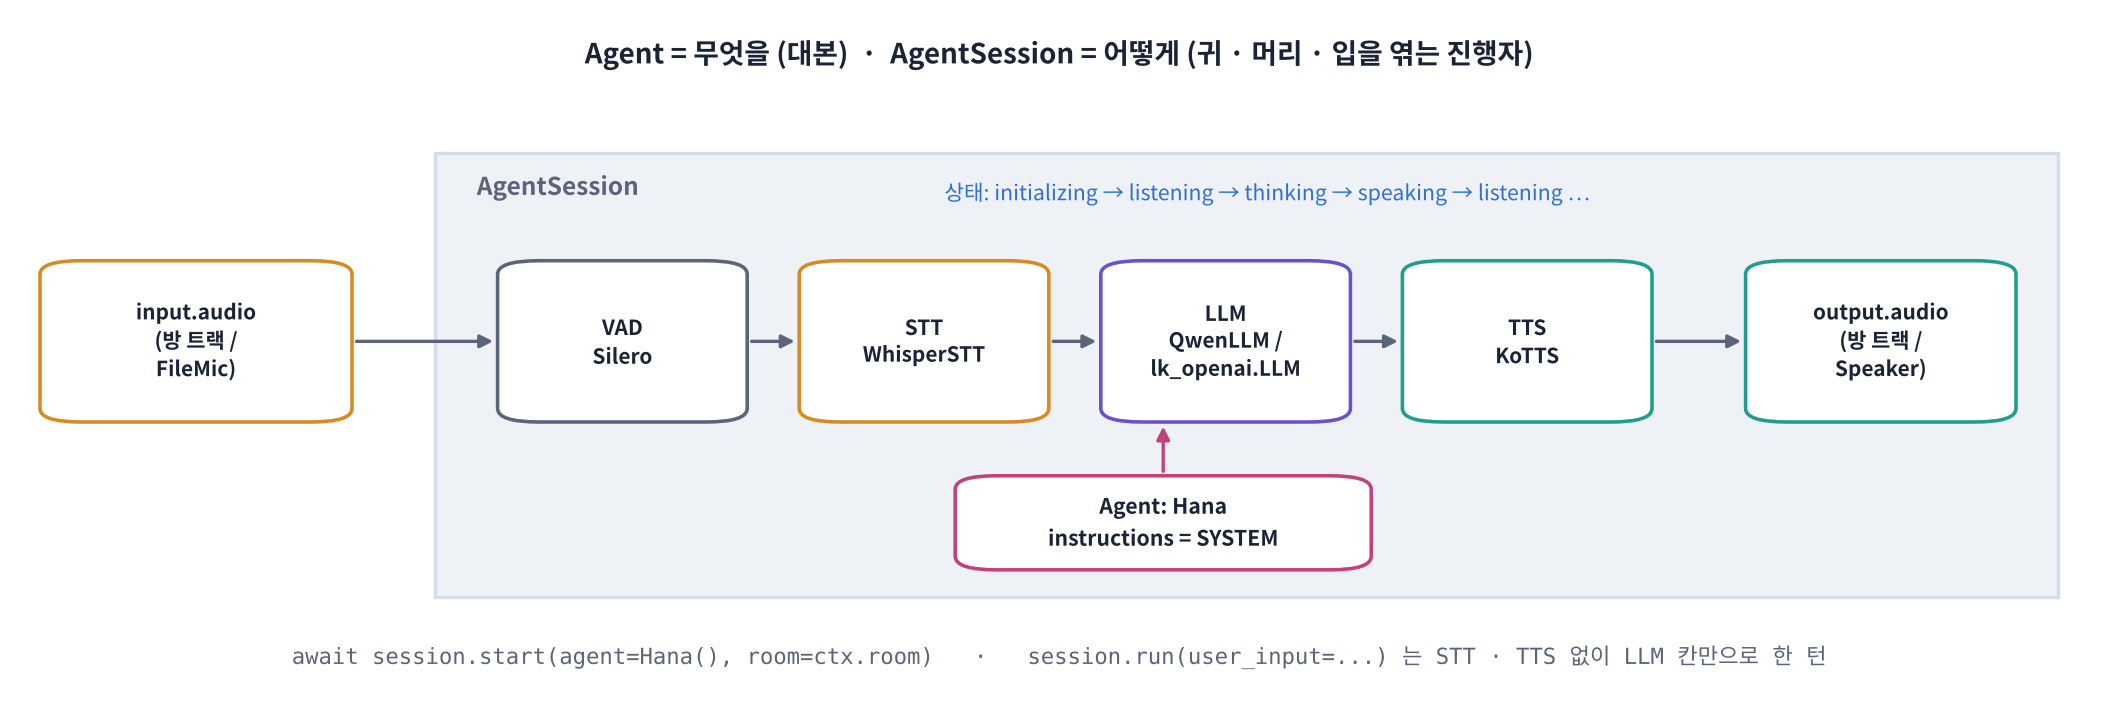

LiveKit Agents의 비서는 **두 가지**로 나뉩니다.

| | **Agent** | **AgentSession** |
|---|---|---|
| 한마디로 | **무엇을** 할지 (역할 · 지시문 · 도구) | **어떻게** 돌릴지 (귀 · 머리 · 입 · 턴 판단을 엮는 진행자) |
| 만드는 법 | `Agent(instructions="...")` 또는 `class Hana(Agent)` | `AgentSession(stt=..., llm=..., tts=..., vad=...)` |
| 바뀌는 때 | 상담 중 '예약 담당 → 수납 담당'처럼 바꿀 수 있음 (D30 Handoff) | 통화 하나에 하나, 통화가 끝나면 닫음 |
| 시작 | | `await session.start(agent=Hana(), room=...)` |

> 🍎 **비유**: 콜센터에서 **Agent는 상담원의 '업무 매뉴얼'**, **AgentSession은 '전화 연결 · 받아쓰기 · 말하기를 해 주는 상담 시스템'** 입니다. 시스템은 그대로 두고 매뉴얼만 바꿔 끼우면 다른 상담원이 됩니다.
>
> 💬 **쉽게 말하면**: Agent = 대본, AgentSession = 무대(조명 · 마이크 · 스피커). 오늘은 대본 하나(`Hana`)를 여러 무대(글자 · 가짜 마이크 · 진짜 방)에 올려 봅니다.

> 🎬 **애니메이션 D29-4:** [Agent와 AgentSession](https://imguru-mooc.github.io/AI_Voice/day29/animation.html#session) — 세션이 귀 · 머리 · 입을 엮고, 상태가 listening → thinking → speaking으로 바뀌는 과정

### 2-1. 머리(LLM) 꽂기: 클라우드는 기성 플러그인, 로컬은 직접 만든 플러그인

- 클라우드 LLM 세 회사는 모두 **OpenAI 호환 주소**를 주므로(D27과 같음), 기성 플러그인 `lk_openai.LLM(model=..., base_url=..., api_key=...)` 하나로 됩니다.
- 로컬 Qwen3는 LiveKit에 플러그인이 없으니 **직접 만듭니다**. 규칙은 단 두 가지입니다.
  1. `llm.LLM`을 물려받고 `chat()`이 **흐름(stream) 객체**를 돌려준다.
  2. 그 흐름은 `llm.LLMStream`을 물려받고 `_run()` 안에서 **조각(`ChatChunk`)을 하나씩 보낸다**.

> 👣 세션이 하는 일: 사용자 말이 들어옴 → 지금까지의 대화(`chat_ctx`)를 들고 `llm.chat()` 호출 → 흐름에서 조각이 나오는 대로 TTS로 넘김. 플러그인은 **조각을 보내는 것까지만** 책임집니다.

> ## 🎤 강사 스크립트 · Part 2 Agent · AgentSession  ⏱️ 6분
>
> 🎯 **Agent = 대본(무엇을), AgentSession = 무대(어떻게).**
>
> 🖥️ [D29-4 Agent와 AgentSession](https://imguru-mooc.github.io/AI_Voice/day29/animation.html#session): 상태 표시등이 listening → thinking → speaking으로 바뀌는 것.
>
> 🗣️ "같은 무대에 대본만 바꿔 올리면 다른 연극이 됩니다. 내일(D30) 예약 담당 → 수납 담당으로 넘기는 Handoff가 바로 '대본 교체'입니다. 오늘 이 둘을 나눠 두는 이유가 거기 있습니다."

In [ ]:
# 🧠 LLM 플러그인: 로컬 Qwen3를 LiveKit 규칙에 맞춰 감싸기 (클라우드는 기성 플러그인)
class QwenLLM(lk_llm.LLM):                                  # 규칙 1: llm.LLM을 물려받고 chat()이 흐름 객체를 돌려줌
    @property
    def model(self): return MODELS["local"]
    def chat(self, *, chat_ctx, tools=None, conn_options=APIConnectOptions(), **kwargs):
        return QwenStream(self, chat_ctx=chat_ctx, tools=tools or [], conn_options=conn_options)

class QwenStream(lk_llm.LLMStream):                         # 규칙 2: _run() 안에서 조각(ChatChunk)을 하나씩 보냄
    async def _run(self):
        messages, _ = self._chat_ctx.to_provider_format("openai")      # 세션이 모은 대화 → [{"role", "content"}, ...]
        messages = [{"role": m["role"], "content": m["content"] if isinstance(m["content"], str) else str(m["content"])}
                    for m in messages if m["role"] in ("system", "user", "assistant")]
        it = qwen_stream(messages)                                    # D27과 같은 생성 함수 (별도 스레드에서 글자를 흘려줌)
        rid = utils.shortuuid()
        while (piece := await asyncio.to_thread(next, it, None)) is not None:
            if piece:
                self._event_ch.send_nowait(lk_llm.ChatChunk(id=rid, delta=lk_llm.ChoiceDelta(role="assistant", content=piece)))

def qwen_stream(messages):
    text = tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True, enable_thinking=False)
    enc = tok(text, return_tensors="pt").to(DEVICE)
    streamer = TextIteratorStreamer(tok, skip_prompt=True, skip_special_tokens=True)
    Thread(target=llm_model.generate, kwargs=dict(**enc, max_new_tokens=80, do_sample=False, repetition_penalty=1.1, streamer=streamer)).start()
    return iter(streamer)

def make_llm():                                          # 오늘 쓸 머리: 키가 있으면 클라우드(기성 플러그인), 없으면 로컬(직접 만든 플러그인)
    if PROVIDER == "local":
        return QwenLLM()
    kw = {"base_url": BASE_URLS[PROVIDER]} if BASE_URLS[PROVIDER] else {}
    return lk_openai.LLM(model=MODELS[PROVIDER], api_key=secret(KEYS[PROVIDER]), **kw)

L = make_llm()
print("LLM 플러그인:", type(L).__module__ + "." + type(L).__name__, "· 모델:", L.model)

> ## 🎤 강사 스크립트 · LLM 플러그인  ⏱️ 7분
>
> 🎯 **플러그인 규칙: 부모 클래스 + 메서드. LLM은 `chat()` → `LLMStream._run()` → `ChatChunk`를 하나씩.**
>
> 🗣️ "어제 Pipecat의 `LocalLLM`은 Frame을 받아 `LLMTextFrame`을 push했죠. 오늘은 `ChatChunk`를 `_event_ch`로 보냅니다. **하는 일은 같고 이름만 다릅니다.** 클라우드 LLM은 기성 플러그인 `lk_openai.LLM`에 base_url만 바꿔 줍니다(D27과 같은 OpenAI 호환 주소)."
>
> ✅ 로컬: `__main__.QwenLLM · 모델: Qwen/Qwen3-1.7B`(T4) / 키: `livekit.plugins.openai.llm.LLM · 모델: …`

### 2-2. 대본 쓰기: Agent

`Agent`에 넘기는 `instructions`가 곧 **시스템 프롬프트**입니다. 세션이 LLM을 부를 때마다 대화 맨 앞에 이 지시문을 붙여 줍니다. 오늘의 지시문은 D27 · D28과 같은 `SYSTEM`(한빛치과 전화 예약 도우미)입니다.

In [ ]:
# 🧩 빈칸 실습 3: 대본(Agent) 쓰기
class Hana(Agent):
    def __init__(self):
        super().__init__(____=SYSTEM)                    # 빈칸 3: 비서의 지시문(시스템 프롬프트)을 넘기는 인자 이름

hana = Hana()
print("지시문 앞부분:", hana.instructions[:40] + "…")
check(hana.instructions == SYSTEM, "Agent에 지시문을 넘기는 인자 이름을 확인하세요.")

> ## 🎤 강사 스크립트 · 빈칸 3  ⏱️ 3분
>
> 🆘 "D22부터 써 온 system 프롬프트를 LiveKit은 '지시 사항'이라는 영어 단어로 부릅니다."
>
> ✅ `지시문 앞부분: 당신은 한빛치과의 …` + ✅

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
class Hana(Agent):
    def __init__(self):
        super().__init__(instructions=SYSTEM)
```

**해설**: `instructions`는 Agent의 필수 인자입니다. 세션은 LLM에 대화를 보낼 때 이 글을 **system 메시지로 맨 앞에** 붙입니다. 같은 세션에 다른 Agent(다른 instructions)를 넣으면 비서의 역할이 바뀝니다(D30 Handoff).

</details>

### 2-3. 글자로 먼저 시험하기: `session.run(user_input=...)`

음성 비서를 만들 때 처음부터 마이크로 시험하면, 문제가 생겼을 때 **귀(STT) 탓인지 머리(LLM) 탓인지** 알기 어렵습니다. LiveKit은 **소리 없이 글자로** 한 턴을 돌려 보는 `session.run()`을 줍니다. 결과(`RunResult`)에는 그 턴에서 일어난 일(메시지 · 도구 호출 등)이 순서대로 담기고, `result.expect`로 **"다음 일은 비서의 메시지여야 한다"** 같은 시험(test)을 쓸 수 있습니다.

> 💬 **쉽게 말하면**: 무대에 올리기 전 **대본 리딩**입니다. STT · TTS 없이 LLM과 대본만으로 대화가 되는지 먼저 봅니다.

> ## 🎤 강사 스크립트 · 대본 리딩  ⏱️ 2분
>
> 🗣️ "마이크로 바로 시험하면, 비서가 엉뚱하게 답했을 때 귀가 잘못 들은 건지 머리가 잘못 생각한 건지 모릅니다. 그래서 글자로 먼저. 실무에서는 이걸 pytest로 돌립니다."

In [ ]:
# 🧩 빈칸 실습 4: 글자로 한 턴 돌리기 (STT · TTS · VAD 없이 LLM만)
async def text_turns(inputs):
    session = AgentSession(llm=make_llm())               # 귀 · 입 없이 머리만 꽂은 세션
    await session.start(agent=Hana())
    rows = []
    for q in inputs:
        t0 = time.perf_counter()
        result = await session.____(user_input=q)        # 빈칸 4: 글자 한 마디를 넣고 그 턴이 끝날 때까지 기다림
        ev = result.expect.next_event().is_message(role="assistant")      # 시험: 다음 일은 '비서의 메시지'여야 함
        msg = ev.event().item
        rows.append({"사용자": q, "비서": msg.text_content, "걸린 시간(초)": round(time.perf_counter() - t0, 2),
                     "LLM TTFT(초)": round((msg.metrics or {}).get("llm_node_ttft", float("nan")), 2)})
    history = [(i.role, i.text_content) for i in session.history.items if i.type == "message"]
    await session.aclose()
    return pd.DataFrame(rows), history

TURNS = ["안녕하세요, 다음 주 수요일 오후 두 시에 스케일링 예약하고 싶어요.", "네, 이름은 김민준이에요.", "주차는 되나요?"]  # ✏️ 바꿔 보기
df_text, history = await text_turns(TURNS)
display(df_text)
print("세션이 기억한 대화:", len(history), "개 메시지 →", [r for r, _ in history])
check(len(df_text) == 3 and len(history) == 6, "session의 '한 턴 돌리기' 메서드 이름을 확인하세요.")

> ## 🎤 강사 스크립트 · 빈칸 4  ⏱️ 7분
>
> 🆘 "한 턴을 '돌린다' = 영어 한 단어."
>
> ✅ (키: 몇 초 / 로컬 T4: 10 ~ 20초) 3줄 표 + `세션이 기억한 대화: 6 개 메시지` + ✅. LLM TTFT는 클라우드 0.3 ~ 0.8초, 로컬 T4 0.1 ~ 0.3초.
>
> ❓ "두 번째 답이 첫 질문을 기억하나요?" → 예. 세션이 `history`를 쌓아 매번 통째로 보냄. 그래서 통화가 길어질수록 입력 토큰이 늘어남(비용 · 지연).

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
result = await session.run(user_input=q)
```

**해설**: `run()`은 `generate_reply(user_input=...)`로 한 턴을 시작하고, 그 턴의 결과를 모으는 `RunResult`를 돌려줍니다. `await`하면 비서의 답이 끝날 때까지 기다립니다. 세션은 대화 기록(`session.history`)을 계속 쌓기 때문에, 두 번째 `run()`의 LLM은 첫 번째 질문과 답을 기억한 채로 답합니다(사용자 3 + 비서 3 = 메시지 6개).

</details>

**❓ 생각해 보기**: `result.expect.next_event().is_message(role="assistant")` 같은 줄은 왜 쓸까요? 그냥 `print`로 답을 눈으로 보면 안 될까요?

<details>
<summary>답 보기</summary>

프롬프트 · 모델 · 플러그인을 바꿀 때마다 수십 가지 대화를 **사람이 눈으로** 확인하기는 어렵습니다. `expect`로 '비서는 반드시 답해야 한다', '여기서는 예약 도구를 불러야 한다'를 적어 두면 **자동 시험(pytest 등)** 으로 매번 돌릴 수 있습니다. LiveKit은 여기에 더해 `judge()`로 'LLM이 답의 품질을 채점'하는 기능도 줍니다. 음성 비서도 일반 소프트웨어처럼 **시험을 먼저 갖춰 두는** 것이 좋습니다.

</details>

> 📝 **워크시트 2교시** 10문항을 풀어 보세요.

> ## 🎤 강사 스크립트 · 토론 + 워크시트 2교시  ⏱️ 5분
>
> ❓ `expect`를 왜 쓰나 → 자동 시험. "프롬프트를 고칠 때마다 사람이 30개 대화를 들어 볼 수는 없다."
>
> 🖥️ [worksheet.html 2교시 탭](https://imguru-mooc.github.io/AI_Voice/day29/worksheet.html)

## Part 3. Plugin 구조: 귀(STT)와 입(TTS)을 직접 만들기, 그리고 방 없이 통화  ·  3교시

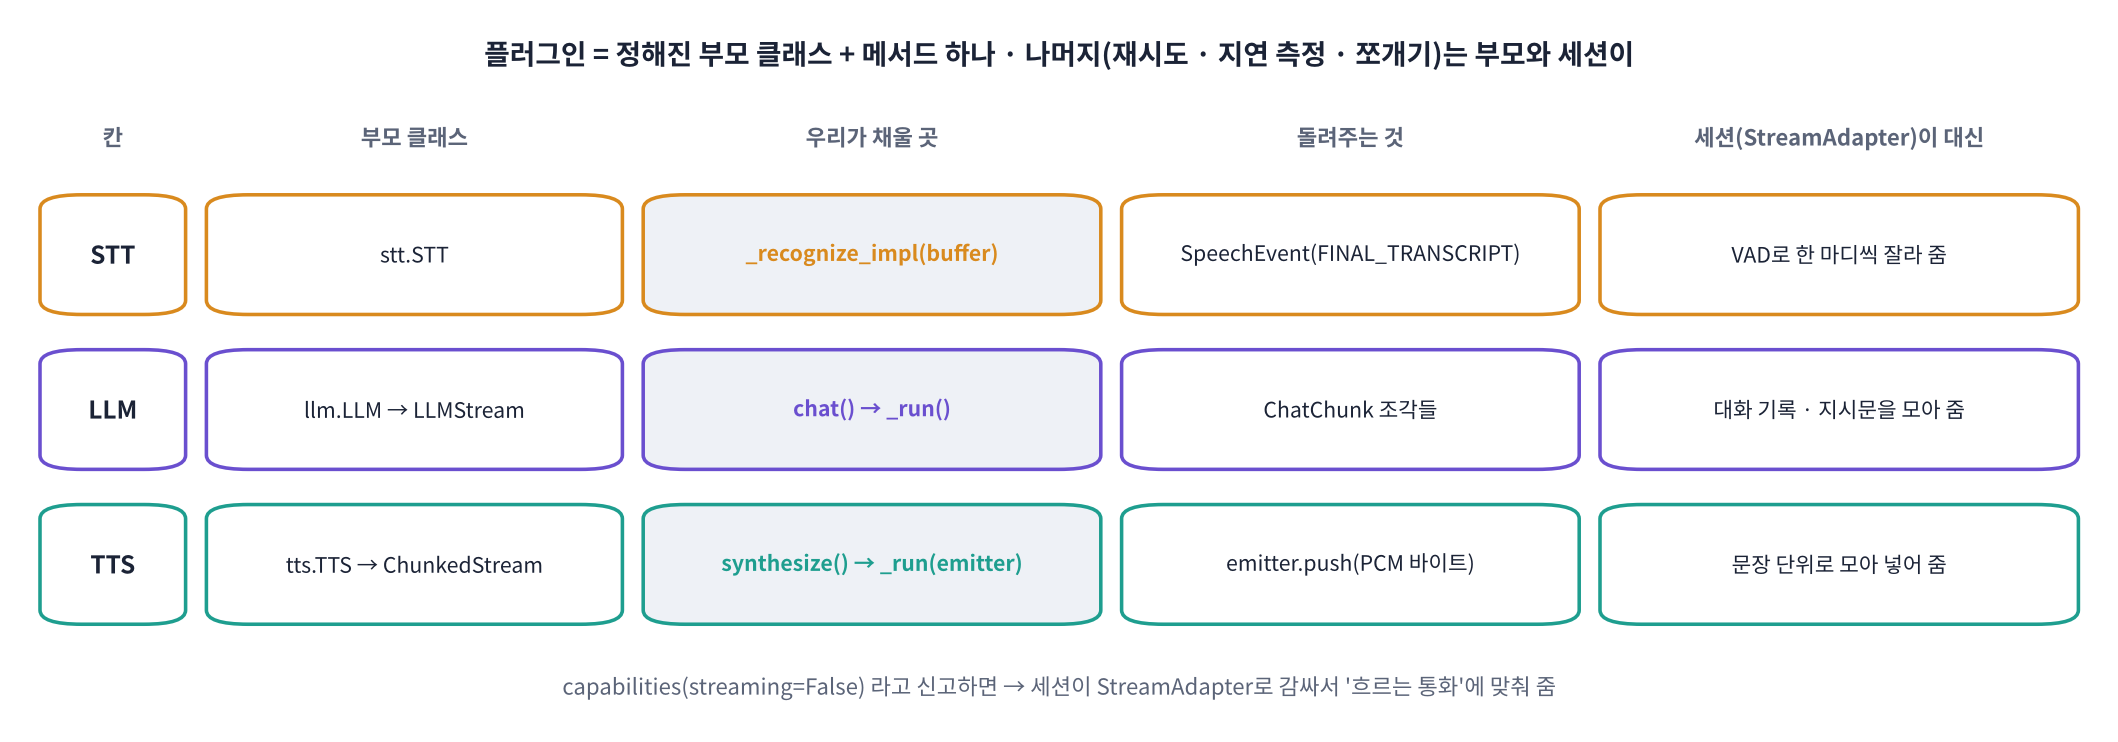

LiveKit의 플러그인은 모두 같은 모양입니다. **정해진 부모 클래스를 물려받고, 정해진 메서드 하나만 채우면** 세션이 나머지(재시도 · 지연 측정 · 쪼개기 · 이어 붙이기)를 맡습니다. (코드에서는 Part 0의 `stt()` · `tts()` 함수와 이름이 겹치지 않도록 `lk_stt` · `lk_tts` · `lk_llm`으로 불러 옵니다.)

| 칸 | 부모 클래스 | 채울 메서드 | 받는 것 → 돌려주는 것 |
|---|---|---|---|
| 귀 STT | `stt.STT` | `_recognize_impl(buffer)` | 소리 조각들 → `SpeechEvent`(받아쓴 글자) |
| 머리 LLM | `llm.LLM` + `llm.LLMStream` | `chat()` + `_run()` | 대화 기록 → `ChatChunk` 조각들 (Part 2-1) |
| 입 TTS | `tts.TTS` + `tts.ChunkedStream` | `synthesize()` + `_run(output_emitter)` | 문장 → `output_emitter.push(소리 바이트)` |
| VAD | `vad.VAD` | (오늘은 기성 `silero.VAD.load()`) | 소리 → 말 시작 · 끝 신호 |

> 🍎 **비유**: 전기 콘센트와 같습니다. 콘센트 모양(부모 클래스 · 메서드 이름)만 맞추면 어느 회사 제품(Whisper든 Deepgram이든)이든 꽂힙니다.
>
> 💬 **쉽게 말하면**: D27의 `run_stt` · `run_tts` 자리가 LiveKit에서는 `_recognize_impl` · `_run`입니다.

> 🎬 **애니메이션 D29-6:** [플러그인의 콘센트](https://imguru-mooc.github.io/AI_Voice/day29/animation.html#plugin) — 부모 클래스 · 채울 메서드 · 세션이 대신해 주는 일 (StreamAdapter)

### 3-1. 귀: Whisper STT 플러그인

- `STTCapabilities(streaming=False, ...)`: "나는 **다 들은 다음 한 번에** 받아쓴다"(Whisper는 실시간 흘려 받아쓰기를 못 함)는 신고입니다.
- 그러면 세션이 **VAD로 말 한 마디씩 잘라** `_recognize_impl`을 불러 줍니다(`StreamAdapter`, 3-3에서 확인).
- 방에서 오는 소리는 보통 **48 kHz 또는 24 kHz**이므로, Whisper에 넣기 전에 16 kHz로 바꿉니다.

> ## 🎤 강사 스크립트 · Part 3 플러그인 구조  ⏱️ 5분
>
> 🎯 **콘센트 모양(부모 클래스 · 메서드 이름)만 맞추면 어떤 회사 제품이든 꽂힌다.**
>
> 🖥️ [D29-6 플러그인의 콘센트](https://imguru-mooc.github.io/AI_Voice/day29/animation.html#plugin): STT · LLM · TTS 줄을 눌러 '우리가 채울 곳'과 '세션이 대신해 주는 일' 비교.
>
> 🗣️ "Deepgram 플러그인을 열어 보면 똑같이 `stt.STT`를 물려받고 `_recognize_impl`과 `stream()`을 채워 놓았습니다. 우리가 오늘 만드는 것이 **진짜 플러그인과 같은 모양**입니다."

In [ ]:
# 🧩 빈칸 실습 5 · 6: 귀(STT) 플러그인
class WhisperSTT(lk_stt.STT):
    def __init__(self):
        super().__init__(capabilities=lk_stt.STTCapabilities(streaming=False, interim_results=False))
    @property
    def model(self): return ASR_NAME

    async def ____(self, buffer, *, language=None, conn_options=None):         # 빈칸 5: 세션이 부르는 '받아쓰기' 메서드 이름
        frame = rtc.combine_audio_frames(buffer)                               # 20 ms 조각들 → 한 덩어리
        y = np.frombuffer(frame.data, dtype=np.int16).astype(np.float32) / 32768
        if frame.num_channels > 1:
            y = y.reshape(-1, frame.num_channels).mean(axis=1)
        if frame.sample_rate != SR:
            y = librosa.resample(y, orig_sr=frame.sample_rate, target_sr=SR)  # 방의 48 kHz → Whisper의 16 kHz
        text = await asyncio.to_thread(stt, y)                                 # Part 0의 Whisper (무거운 일은 스레드로)
        return lk_stt.SpeechEvent(type=lk_stt.SpeechEventType.____,                 # 빈칸 6: '확정된 받아쓰기' 사건 종류
                               alternatives=[lk_stt.SpeechData(language="ko", text=text)])

def to_frames(y, sr=SR, ms=20):                          # numpy 소리 → LiveKit의 소리 조각(rtc.AudioFrame) 목록
    n = sr * ms // 1000
    pcm = (np.clip(to_np(y), -1, 1) * 32767).astype(np.int16)
    pcm = np.pad(pcm, (0, -len(pcm) % n))
    return [rtc.AudioFrame(pcm[i:i + n].tobytes(), sr, 1, n) for i in range(0, len(pcm), n)]

ear = WhisperSTT()
frames = to_frames(VOICE1)
t0 = time.perf_counter()
ev = await ear.recognize(frames)                         # 부모 클래스의 recognize() → 재시도 · 지연 측정 → 우리의 메서드
print(f"조각 {len(frames)}개 ({len(frames) * 0.02:.1f}초) → [{ev.type.value}] {ev.alternatives[0].text!r} · {time.perf_counter() - t0:.2f}초")
frames48 = to_frames(librosa.resample(VOICE1, orig_sr=SR, target_sr=48000), sr=48000)
ev48 = await ear.recognize(frames48)
print("48 kHz로 와도:", repr(ev48.alternatives[0].text))
check(ev.type == lk_stt.SpeechEventType.FINAL_TRANSCRIPT and len(ev.alternatives[0].text) > 0,
      "세션이 부르는 메서드 이름(밑줄로 시작)과 '확정' 사건 종류를 확인하세요.")

> ## 🎤 강사 스크립트 · 빈칸 5 · 6  ⏱️ 8분
>
> 🆘 빈칸 5: "바깥 이름은 `recognize`, 안쪽 자리는 밑줄 + recognize + impl(구현)". 빈칸 6: "확정 = FINAL, 받아쓰기 = TRANSCRIPT".
>
> ✅ `조각 190개 (3.8초) → [final_transcript] '안녕하세요, 다음 주 수요일 …'` 과 48 kHz 결과가 거의 같음 + ✅.
>
> ⚠️ 빈칸 5에 `recognize`를 넣으면 부모 메서드를 덮어써서 재시도 · metrics가 사라지거나 무한 재귀. "밑줄 메서드 = 우리가 채우는 자리, 밑줄 없는 메서드 = 남이 부르는 문".

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
async def _recognize_impl(self, buffer, *, language=None, conn_options=None):
    ...
    return lk_stt.SpeechEvent(type=lk_stt.SpeechEventType.FINAL_TRANSCRIPT, alternatives=[...])
```

**해설**: 바깥에서 부르는 것은 부모의 `recognize()`이고, 부모가 재시도 · 지연 측정(metrics)을 한 뒤 **우리의 `_recognize_impl()`** 을 부릅니다(밑줄 = '안에서 쓰는 자리'). 사건 종류는 `START_OF_SPEECH` · `INTERIM_TRANSCRIPT`(중간 받아쓰기) · `FINAL_TRANSCRIPT`(확정) · `END_OF_SPEECH` 등이 있고, Whisper처럼 한 번에 받아쓰는 STT는 **확정 하나**만 돌려주면 됩니다. 확정 글자가 있어야 세션이 사용자 턴을 끝내고 LLM을 부릅니다.

</details>

### 3-2. 입: Edge TTS 플러그인

TTS는 두 층입니다. `tts.TTS`가 **설정**(표본율 · 채널 · 스트리밍 가능 여부)을 들고, `synthesize(text)`가 부를 때마다 **한 문장짜리 일감** `tts.ChunkedStream`을 만듭니다. 일감의 `_run(output_emitter)` 안에서 할 일은 세 줄입니다.

👣 **한 단계씩**: ① `output_emitter.initialize(...)` (이 소리는 16 kHz · 모노 · PCM이다) → ② `output_emitter.push(소리 바이트)` (만든 소리를 밀어 넣기, 여러 번 가능) → ③ `output_emitter.flush()` (이 문장 끝)

In [ ]:
# 🧩 빈칸 실습 7: 입(TTS) 플러그인
class KoTTS(lk_tts.TTS):
    def __init__(self):
        super().__init__(capabilities=lk_tts.TTSCapabilities(streaming=False), sample_rate=SR, num_channels=1)
    @property
    def model(self): return "edge-tts " + VOICE_BOT if TTS_ENGINE == "edge" else "mms-tts-kor"
    def synthesize(self, text, *, conn_options=APIConnectOptions()):
        return KoChunk(tts=self, input_text=text, conn_options=conn_options)

class KoChunk(lk_tts.ChunkedStream):
    async def _run(self, output_emitter):
        y = await asyncio.to_thread(tts, normalize_ko(self.input_text))       # Part 0의 Edge TTS (숫자는 읽는 말로)
        pcm = (np.clip(y, -1, 1) * 32767).astype(np.int16).tobytes()
        output_emitter.initialize(request_id=utils.shortuuid(), sample_rate=SR, num_channels=1, mime_type="audio/pcm")
        output_emitter.____(pcm)                                               # 빈칸 7: 만든 소리를 밀어 넣기
        output_emitter.flush()

mouth = KoTTS()
t0 = time.perf_counter(); got = []
async for audio in mouth.synthesize("네, 다음 주 수요일 오후 2시로 예약해 드릴게요."):    # 일감에서 소리 조각(SynthesizedAudio)이 나옴
    got.append(np.frombuffer(audio.frame.data, dtype=np.int16).astype(np.float32) / 32768)
y_bot = np.concatenate(got) if got else np.zeros(0, np.float32)
print(f"소리 조각 {len(got)}개 · {len(y_bot) / SR:.2f}초 · 첫 조각까지 {time.perf_counter() - t0:.2f}초")
play(y_bot, SR, "KoTTS 플러그인이 만든 소리")
check(len(y_bot) > SR * 0.5, "output_emitter에 소리 바이트를 '밀어 넣는' 메서드 이름을 확인하세요.")

> ## 🎤 강사 스크립트 · 빈칸 7  ⏱️ 5분
>
> 🆘 "소리를 emitter에 '밀어 넣는다' = 영어 한 단어 (스택에서도 쓰는 말)."
>
> ✅ `소리 조각 10 ~ 20개 · 2 ~ 3초`, 🎧 사람 목소리 + ✅.
>
> 🗣️ "Edge TTS는 MP3를 통째로 받아 한 번에 push했지만, 클라우드 TTS가 조금씩 보내 주면 받을 때마다 push하면 됩니다. 그러면 첫 소리(TTFB)가 빨라집니다."

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
output_emitter.push(pcm)
```

**해설**: `push()`는 소리 바이트를 받아 세션이 쓰는 **소리 조각(`rtc.AudioFrame`)으로 잘라** 내보냅니다. 클라우드 TTS처럼 소리가 조금씩 도착하면 도착할 때마다 `push()`를 여러 번 부르면 되고, 그러면 **첫 소리가 빨리** 나갑니다(TTFB). MP3 · Opus 같은 압축 소리도 `mime_type`만 맞게 주면 emitter가 풀어 줍니다.

</details>

### 3-3. 세션이 대신해 주는 일: StreamAdapter

우리 플러그인은 둘 다 `streaming=False`(한 번에 처리)라고 신고했습니다. 그런데 통화는 **끝없이 흐르는 소리 · 글자**입니다. 세션은 이 차이를 **StreamAdapter**로 메웁니다.

| | 들어오는 것 | StreamAdapter가 하는 일 | 그다음 |
|---|---|---|---|
| STT | 끝없는 마이크 소리 | **VAD**로 말 한 마디씩 잘라서 | `_recognize_impl` 한 번씩 |
| TTS | LLM이 흘려 주는 글자 조각 | **문장 단위**로 모아서 | `synthesize(문장)` 한 번씩 |

> 💬 **쉽게 말하면**: 우리는 '한 마디 받아쓰기' · '한 문장 읽기'만 만들면, 세션이 **잘라서 넣어 주고 이어서 내보냅니다**. 그래서 LLM이 첫 문장을 다 쓰자마자 TTS가 읽기 시작합니다.

### 3-4. 방 없이 통화하기: 가짜 마이크(AudioInput) · 가짜 스피커(AudioOutput)

세션은 소리를 **입력 자리 `session.input.audio`** 에서 받고 **출력 자리 `session.output.audio`** 로 내보냅니다. 방에 연결하면 이 두 자리에 '방의 트랙'이 꽂히지만, 우리가 만든 것을 꽂을 수도 있습니다.

- `FileMic`: 녹음해 둔 사용자 말을 **20 ms 조각, 실제 시간 속도**로 흘려보냅니다. 비서가 말을 마치고 듣는 중(`listening`)이 되면 다음 말을 시작하는 **예의 바른 사용자**입니다.
- `Speaker`: 받은 소리를 **실제 재생 시간만큼 기다렸다가** '재생 끝'을 알립니다. 세션은 이 신호를 보고 비서의 말이 끝났다고 판단합니다.

> 🎬 **애니메이션 D29-5:** [세션 안의 흐름](https://imguru-mooc.github.io/AI_Voice/day29/animation.html#pipeline) — 마이크 → VAD → STT → LLM → TTS → 스피커, 그리고 턴마다 재는 지연

> ## 🎤 강사 스크립트 · StreamAdapter · 가짜 입출력  ⏱️ 4분
>
> 🖥️ [D29-5 세션 안의 흐름](https://imguru-mooc.github.io/AI_Voice/day29/animation.html#pipeline): ▶ 재생 → VAD가 말 한 마디를 자르고 → STT → LLM 조각 → 문장 → TTS.
>
> 🗣️ "세션의 입력 자리와 출력 자리에 방 대신 우리가 만든 마이크 · 스피커를 꽂습니다. 이게 되면 **서버 없이도** 통화 전체를 시험할 수 있습니다. 실무에서 아주 많이 쓰는 방법입니다."

In [ ]:
# 🎙️ 가짜 마이크 · 가짜 스피커 + 통화 기록기 (Part 3 · 4에서 같이 씀)
class FileMic(lk_io.AudioInput):
    # 녹음해 둔 말들을 실제 시간 속도의 20 ms 조각으로. 비서가 한 번 말하고 다시 듣는 중이 된 뒤 gap초가 지나면 다음 말을 시작
    def __init__(self, session, voices, gap=0.8, wait_bot=True):
        super().__init__(label="file-mic")
        self.s, self.queue, self.gap = session, list(voices), gap
        self.n = SR // 50; self.k = 0; self.t0 = None
        self.cur, self.pos, self.spans = None, 0, []
        self.need_bot = wait_bot; self.quiet_since = None
    def finished(self):
        return not self.queue and self.cur is None and not self.need_bot and self.s.agent_state == "listening"
    async def __anext__(self):
        if self.t0 is None: self.t0 = time.perf_counter()
        self.k += 1
        await asyncio.sleep(max(0.0, self.t0 + self.k * self.n / SR - time.perf_counter()))   # 실제 시간 속도
        now = time.perf_counter() - self.t0
        state = self.s.agent_state
        if state == "speaking": self.need_bot = False
        if self.cur is None and self.queue and not self.need_bot:
            if state == "listening":
                self.quiet_since = self.quiet_since if self.quiet_since is not None else now
                if now - self.quiet_since >= self.gap:
                    self.cur, self.pos = self.queue.pop(0), 0; self.spans.append([now, None])
            else:
                self.quiet_since = None
        if self.cur is not None:
            chunk = self.cur[self.pos:self.pos + self.n]; self.pos += self.n
            if self.pos >= len(self.cur):
                self.spans[-1][1] = now + len(chunk) / SR; self.cur = None; self.need_bot = True; self.quiet_since = None
        else:
            chunk = np.zeros(0, np.float32)
        chunk = np.pad(chunk, (0, self.n - len(chunk)))
        return rtc.AudioFrame((np.clip(chunk, -1, 1) * 32767).astype(np.int16).tobytes(), SR, 1, self.n)

class Speaker(lk_io.AudioOutput):
    # 받은 소리를 '실제 재생 시간'만큼 기다렸다가 재생 끝을 알리는 가짜 스피커 (받은 소리는 시각과 함께 보관)
    def __init__(self, t0):
        super().__init__(label="speaker", capabilities=lk_io.AudioOutputCapabilities(pause=False), sample_rate=SR)
        self.t0 = t0; self.chunks = []; self.seg_start = None; self.seg_len = 0.0; self.task = None
    async def capture_frame(self, frame):
        await super().capture_frame(frame)
        now = time.perf_counter()
        if self.seg_start is None:
            self.seg_start = now; self.on_playback_started(created_at=time.time())
        y = np.frombuffer(frame.data, dtype=np.int16).astype(np.float32) / 32768
        self.chunks.append((self.seg_start - self.t0 + self.seg_len, y))   # 이 조각이 '재생되는' 시각
        self.seg_len += len(y) / frame.sample_rate
    def flush(self):
        super().flush()
        if self.seg_start is None: return
        start, length = self.seg_start, self.seg_len
        async def finish():
            await asyncio.sleep(max(0.0, start + length - time.perf_counter()))
            self.seg_start, self.seg_len = None, 0.0
            self.on_playback_finished(playback_position=length, interrupted=False)
        self.task = asyncio.ensure_future(finish())
    def clear_buffer(self):                              # 끼어들기: 남은 소리를 버리고 '여기까지 재생됨'을 알림
        if self.seg_start is None: return
        if self.task: self.task.cancel()
        pos = min(self.seg_len, time.perf_counter() - self.seg_start)
        self.chunks = [(t, y) for t, y in self.chunks if t < self.seg_start - self.t0 + pos]
        self.seg_start, self.seg_len = None, 0.0
        self.on_playback_finished(playback_position=pos, interrupted=True)

class CallLog:                                           # 세션의 사건(event)을 시각과 함께 적어 두기
    def __init__(self, session, t0):
        self.t0, self.states, self.items = t0, [], []
        session.on("agent_state_changed", lambda ev: self.states.append((time.perf_counter() - self.t0, ev.new_state)))
        session.on("conversation_item_added", lambda ev: self.items.append(ev.item) if ev.item.type == "message" else None)

VAD = silero.VAD.load()                                  # 기성 플러그인: Silero VAD (D19 · D28과 같은 모델)
def make_session():                                      # 오늘의 세션: 귀 · 머리 · 입 · VAD
    return AgentSession(stt=WhisperSTT(), llm=make_llm(), tts=KoTTS(), vad=VAD)

def attach_fake_io(session, voices, t0):
    mic, spk = FileMic(session, voices), Speaker(t0)
    mic.t0 = t0                                          # 마이크 · 스피커가 같은 시계(t0)를 씀
    session.input.audio, session.output.audio = mic, spk
    return mic, spk

async def wait_call(mic, max_wait=90, tail=1.0):
    t_end = time.perf_counter() + max_wait
    while time.perf_counter() < t_end and not mic.finished():
        await asyncio.sleep(0.1)
    await asyncio.sleep(tail)
print("준비 완료: FileMic · Speaker · CallLog · make_session()")

> ## 🎤 강사 스크립트 · FileMic · Speaker  ⏱️ 3분
>
> 🗣️ "코드는 길지만 하는 일은 단순합니다. FileMic은 20 ms마다 소리 조각 하나를 돌려주고, 비서가 말을 마치면 다음 말을 시작합니다. Speaker는 받은 소리 길이만큼 기다렸다가 '다 재생했다'고 알립니다. 이 신호가 없으면 세션은 비서가 아직 말하는 중이라고 생각합니다."
>
> ✅ `준비 완료: FileMic · Speaker · CallLog · make_session()`

In [ ]:
# ▶️ 방 없이 음성 통화: 인사 → 사용자 말 1 → 비서 답 → 사용자 말 2 → 비서 답  (실제 시간, 약 20 ~ 40초)
async def local_call(voices=(VOICE1, VOICE2), greet=GREET):
    session = make_session(); t0 = time.perf_counter()
    log = CallLog(session, t0)
    mic, spk = attach_fake_io(session, voices, t0)
    await session.start(agent=Hana())                    # room을 주지 않으면 우리가 꽂은 입출력 자리를 그대로 씀
    if greet: session.say(greet)                         # LLM을 거치지 않고 정해진 문장을 바로 말하기
    await wait_call(mic)
    await session.aclose()
    return dict(log=log, mic=mic, spk=spk)

def bot_spans(chunks, gap=0.3):                          # 받은 소리 조각 → 비서가 말한 구간 [(시작, 끝)]
    spans = []
    for t, y in chunks:
        a, b = t, t + len(y) / SR
        if spans and a - spans[-1][1] < gap: spans[-1][1] = b
        else: spans.append([a, b])
    return spans

def turn_table(res):                                     # 메시지마다 붙은 metrics → 턴별 지연 표
    rows = []
    for it in res["log"].items:
        m = it.metrics or {}
        if it.role == "user":
            rows.append({"누가": "사용자", "말": it.text_content[:28], "받아쓰기 지연": m.get("transcription_delay"), "턴 끝 판단 지연": m.get("end_of_turn_delay")})
        elif it.role == "assistant":
            rows.append({"누가": "비서", "말": it.text_content[:28], "LLM 첫 글자 TTFT": m.get("llm_node_ttft"), "TTS 첫 소리 TTFB": m.get("tts_node_ttfb"),
                         "말 끝 → 첫 소리 e2e": m.get("e2e_latency")})
    cols = ["누가", "말", "받아쓰기 지연", "턴 끝 판단 지연", "LLM 첫 글자 TTFT", "TTS 첫 소리 TTFB", "말 끝 → 첫 소리 e2e"]
    return pd.DataFrame(rows, columns=cols).round(2)

def plot_call(res, title=""):
    spans_b = bot_spans(res["spk"].chunks); spans_u = [s for s in res["mic"].spans if s[1]]
    fig, ax = plt.subplots(figsize=(12, 2.6))
    for a, b in spans_b: ax.barh(1, b - a, left=a, color="#1E9E8F", height=0.5)
    for a, b in spans_u: ax.barh(0, b - a, left=a, color="#D98A1E", height=0.5)
    col = {"listening": "#2F6FD6", "thinking": "#6A4FCF", "speaking": "#1E9E8F", "initializing": "#999999"}
    for t, s in res["log"].states:
        ax.axvline(t, color=col.get(s, "#999"), lw=0.8, ls=":"); ax.text(t, 1.45, s[:5], fontsize=7, color=col.get(s, "#999"), rotation=90, va="bottom")
    ax.set_yticks([0, 1]); ax.set_yticklabels(["user (mic)", "bot (speaker)"]); ax.set_xlabel("seconds")   # 그림 글자는 영어 (Colab 기본 글꼴에 한글이 없음)
    ax.set_ylim(-0.5, 2.3); ax.set_title(title, fontsize=10); plt.tight_layout(); plt.show()
    return spans_b, spans_u

def mix(res):                                            # 사용자 말 + 비서 말을 한 줄로 (🎧 통화 녹음처럼)
    end = max([t + len(y) / SR for t, y in res["spk"].chunks] + [s[1] for s in res["mic"].spans if s[1]] + [1])
    out = np.zeros(int(end * SR) + SR, np.float32)
    for t, y in res["spk"].chunks:
        i = int(t * SR); out[i:i + len(y)] += y[:len(out) - i]
    for (a, b), v in zip(res["mic"].spans, [VOICE1, VOICE2]):
        if b: i = int(a * SR); out[i:i + len(v)] += v[:len(out) - i] * 0.9
    return out / (np.abs(out).max() + 1e-9) * 0.9

res_local = await local_call()
spans_b, spans_u = plot_call(res_local, "no room: bot spans (top) · user spans (bottom) · dotted = agent_state")
display(turn_table(res_local))
play(mix(res_local), SR, "통화 전체 (사용자 + 비서)")
print("비서가 말한 구간:", len(spans_b), "· 사용자가 말한 구간:", len(spans_u))

> ## 🎤 강사 스크립트 · 방 없이 통화  ⏱️ 7분
>
> ✅ (20 ~ 40초) 그림: 위 줄 초록 막대 3개(인사 · 답 1 · 답 2), 아래 줄 주황 2개. 표 5줄, e2e 1 ~ 2.5초. 🎧 통화 전체.
>
> ❓ "D28에서 잰 '말 끝 → 첫 소리'와 비교하면?" → 비슷해야 정상(같은 모델). 다르면 턴 판단 기본값 차이.
>
> ⚠️ `resume_false_interruption … ignored` 같은 경고가 나오면 무시해도 됨(가짜 스피커가 '일시정지'를 지원하지 않는다는 뜻).

📐 **핵심 식 하나**: `e2e_latency ≈ 턴 끝 판단 지연 + LLM 첫 글자(TTFT) + 첫 문장 완성 + TTS 첫 소리(TTFB)`

> 💬 표의 `e2e`가 D28에서 `UserBotLatencyObserver`로 잰 **'말 끝 → 첫 소리'** 와 같은 값입니다. LiveKit은 메시지마다 `metrics`로 붙여 줍니다.

**❓ 생각해 보기**: 비서 말 사이사이에 `listening → thinking → speaking`이 반복됩니다. 사용자 말이 끝난 직후에도 한동안 `listening`인 까닭은 무엇일까요?

<details>
<summary>답 보기</summary>

세션은 말소리가 멈춘 순간 바로 턴을 끝내지 않습니다. VAD가 '조용함'을 확인하고(D28의 `stop_secs`처럼), STT의 **확정 받아쓰기**가 도착하고, 턴 끝 판단(기본: 일정 시간 조용하면 끝)이 끝나야 `thinking`으로 넘어갑니다. 그 시간이 표의 '턴 끝 판단 지연'입니다. 이 값을 줄이면 빨라지지만, 말 중간에 쉬는 사람의 말을 끊어 먹습니다(D28 Part 2와 같은 저울질).

</details>

> 📝 **워크시트 3교시** 10문항을 풀어 보세요.

> ## 🎤 강사 스크립트 · 토론 + 워크시트 3교시  ⏱️ 5분
>
> ❓ 말 끝 직후에도 listening인 이유 → 턴 끝 판단 대기 + 확정 받아쓰기 대기.
>
> 🖥️ [worksheet.html 3교시 탭](https://imguru-mooc.github.io/AI_Voice/day29/worksheet.html)

## Part 4. Agent Worker: 방이 생기면 비서가 출근한다  ·  4교시

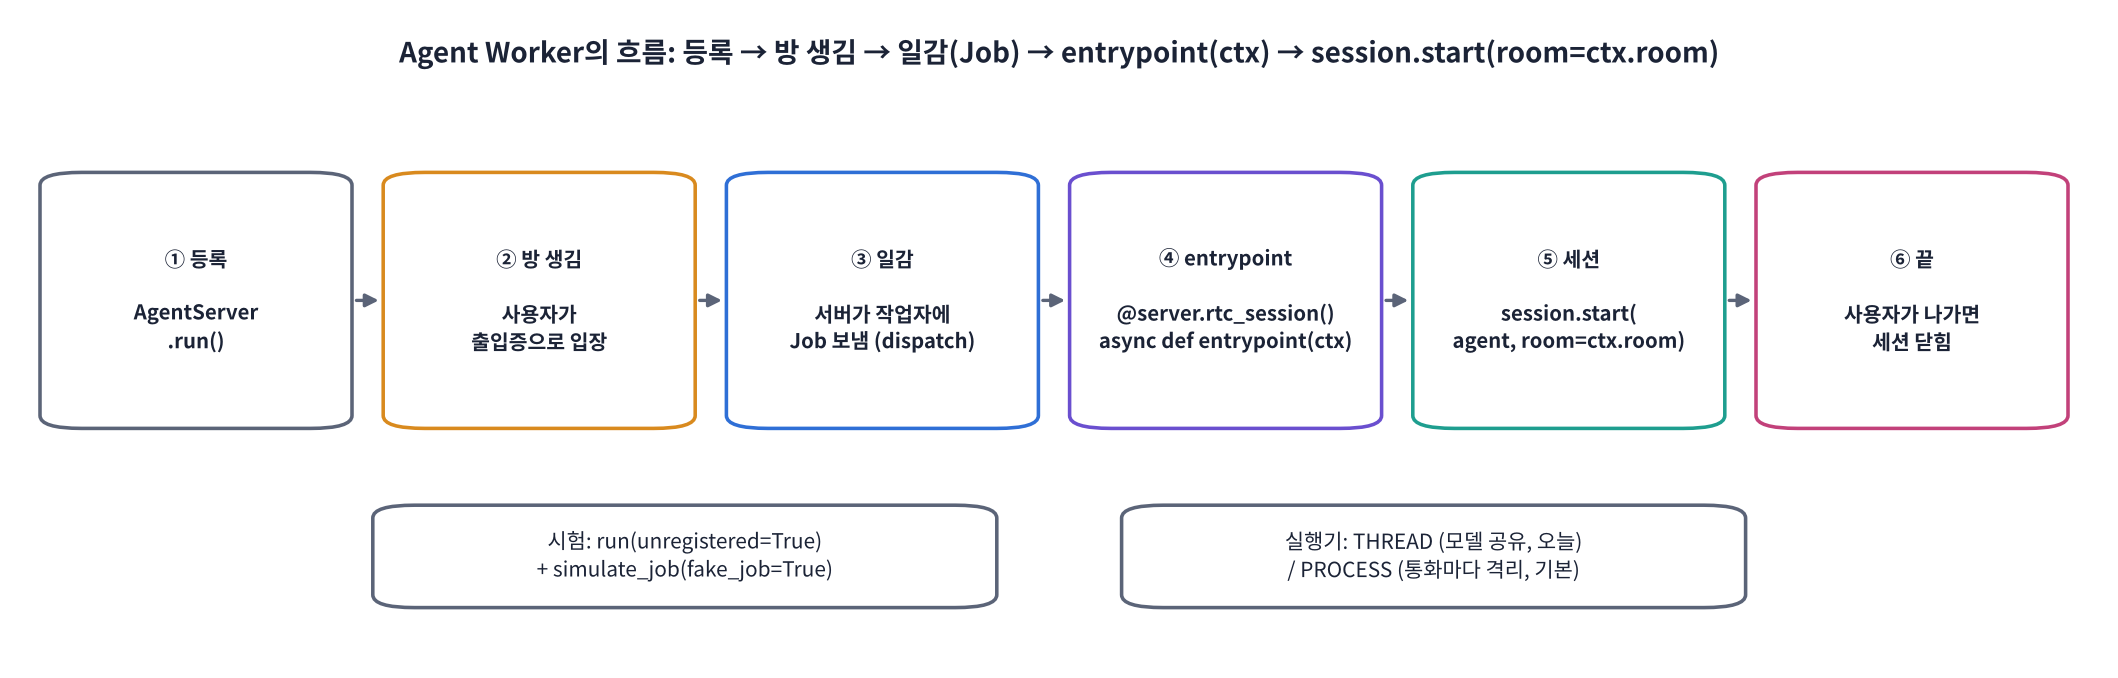

지금까지는 노트북이 세션을 **직접** 만들었습니다. 서비스에서는 통화가 언제 올지 모르므로, **작업자(Worker)** 를 띄워 두고 기다립니다.

👣 **한 단계씩**
1. **등록**: 작업자(`AgentServer`)가 LiveKit 서버에 접속해 "저 일할 수 있어요"라고 등록합니다.
2. **방 생김**: 사용자가 방에 들어오면 LiveKit 서버가 등록된 작업자 중 하나에게 **일감(Job)** 을 보냅니다(dispatch).
3. **entrypoint**: 작업자는 일감마다 우리가 등록한 함수 `entrypoint(ctx)`를 부릅니다. `ctx`(JobContext)에는 **배정된 방**(`ctx.room`)이 들어 있습니다.
4. **세션 시작**: `entrypoint` 안에서 세션을 만들고 `session.start(agent=..., room=ctx.room)` → 세션이 방의 사용자 마이크 트랙을 구독하고, 비서의 목소리 트랙을 publish합니다.

> 🍎 **비유**: 콜센터 상담원(작업자)이 출근해서 대기 명단에 이름을 올리고(등록), 전화가 오면(방 생김) 배정을 받아(일감) 통화를 시작합니다(entrypoint). 한 상담원이 동시에 여러 통화를 받을 수도 있습니다(작업자 하나 = 일감 여러 개).
>
> 💬 **쉽게 말하면**: `entrypoint`는 **'전화 한 통이 오면 할 일'** 을 적은 함수이고, `AgentServer`는 **그 함수를 들고 기다리는 상담원**입니다.

> 🎬 **애니메이션 D29-7:** [작업자의 하루](https://imguru-mooc.github.io/AI_Voice/day29/animation.html#worker) — 등록 → 방 생김 → 일감 → entrypoint → 세션 → 끊김, 그리고 fake job

### 4-1. 작업자 만들고 '가짜 일감(fake job)'으로 시험하기

진짜 LiveKit 서버 없이도 작업자를 시험할 수 있습니다. `run(unregistered=True)`는 서버에 등록하지 않고 작업자만 켜고, `simulate_job(..., fake_job=True)`는 **가짜 방**을 넣어 `entrypoint`를 불러 줍니다. 가짜 방에는 사용자가 없으므로, 그때만 Part 3의 가짜 마이크 · 스피커를 꽂습니다.

> ⚙️ `JobExecutorType.THREAD`: 일감을 **같은 프로그램 안의 스레드**에서 돌립니다. 그래서 Part 0에서 불러 둔 Whisper · Qwen3를 그대로 씁니다. (실서비스 기본값은 `PROCESS`: 일감마다 따로 된 프로세스 → 한 통화가 죽어도 다른 통화는 안전, 대신 모델은 `setup_fnc`(prewarm)에서 미리 불러 둠)

> ## 🎤 강사 스크립트 · Part 4 Agent Worker  ⏱️ 5분
>
> 🎯 **entrypoint = '전화 한 통이 오면 할 일'.**
>
> 🖥️ [D29-7 작업자의 하루](https://imguru-mooc.github.io/AI_Voice/day29/animation.html#worker): ▶ 등록 → 방 생김 → Job → entrypoint → 세션 → 끊김. 'fake job' 버튼으로 서버 없이 도는 경로도.
>
> 🗣️ "Worker 하나가 통화 여러 개를 받습니다. 실서비스 기본값은 통화마다 별도 프로세스(PROCESS) — 한 통화가 죽어도 다른 통화는 안전하게. 오늘은 Colab에 불러 둔 모델을 같이 쓰려고 THREAD."

In [ ]:
# 🧩 빈칸 실습 8 · 9: 작업자(AgentServer)와 entrypoint
server = AgentServer(job_executor_type=JobExecutorType.THREAD)
CALLS = {}                                               # 일감(방)마다 통화 기록을 모아 둠

@server.____()                                           # 빈칸 8: '방 통화 일감이 오면 이 함수를 불러라'라고 등록하는 장식자
async def entrypoint(ctx: JobContext):
    await ctx.connect()                                  # 배정된 방에 접속 (fake job이면 접속하는 척)
    session = make_session(); t0 = time.perf_counter()
    rec = dict(log=CallLog(session, t0), room=ctx.room.name, fake=ctx.is_fake_job())
    if ctx.is_fake_job():                                # 가짜 방에는 사용자가 없음 → 가짜 마이크 · 스피커를 꽂음
        rec["mic"], rec["spk"] = attach_fake_io(session, [VOICE1, VOICE2], t0)
    CALLS[ctx.job.id] = rec
    await session.start(agent=Hana(), room=____)         # 빈칸 9: 세션을 '배정된 방'에 올리기
    session.say(GREET)
    if ctx.is_fake_job():
        await wait_call(rec["mic"]); await session.aclose(); rec["done"] = True

worker_task = asyncio.ensure_future(server.run(devmode=True, unregistered=True))   # LiveKit 서버에 등록하지 않고 작업자만 켜기
await asyncio.sleep(1.0)
await server.simulate_job("hanbit-fake-room", fake_job=True)                       # 가짜 일감 하나 넣기
t_end = time.perf_counter() + 120
while time.perf_counter() < t_end and not any(r.get("done") for r in CALLS.values()):
    await asyncio.sleep(0.2)
job_id, res_fake = next((k, r) for k, r in CALLS.items() if r.get("fake"))
print("일감:", job_id, "· 방 이름:", res_fake["room"], "· fake:", res_fake["fake"])
plot_call(res_fake, "fake job: worker → entrypoint(ctx) → session")
display(turn_table(res_fake))
check(res_fake.get("done") and len([i for i in res_fake["log"].items if i.role == "assistant"]) >= 2,
      "rtc_session 장식자 이름과, JobContext에서 배정된 방을 꺼내는 이름(ctx.room)을 확인하세요.")
await server.aclose()

> ## 🎤 강사 스크립트 · 빈칸 8 · 9  ⏱️ 8분
>
> 🆘 빈칸 8: "rtc(실시간 통신) + session". 빈칸 9: "JobContext에 들어 있는 **배정된 방**".
>
> ✅ (약 30초) `일감: mock-job-… · 방 이름: console · fake: True`, 그림과 표가 Part 3와 비슷 + ✅.
>
> ⚠️ 방 이름이 `console`인 것은 정상: fake job은 콘솔 모드용 가짜 방을 씀.

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
@server.rtc_session()
async def entrypoint(ctx: JobContext):
    ...
    await session.start(agent=Hana(), room=ctx.room)
```

**해설**: `@server.rtc_session()`은 'WebRTC 방 통화(ROOM) 일감이 오면 이 함수를 불러라'라는 등록입니다(`agent_name="..."`을 주면 이름으로 불러야만 오는 **명시적 배정**이 됩니다). `ctx.room`은 이 일감에 배정된 `rtc.Room`이고, `session.start(room=ctx.room)`을 하면 세션이 그 방의 **사용자 마이크 트랙을 구독**하고 **비서의 목소리 트랙을 publish**하며, 비서 상태를 참가자 속성(`lk.agent.state`)으로 방에 알립니다. 가짜 방에서는 우리가 미리 꽂은 FileMic · Speaker가 그대로 쓰입니다.

</details>

### 4-2. 진짜 방: 이 Colab 안에 LiveKit 서버를 띄우고, Python 참가자로 전화 걸기

이번에는 진짜 LiveKit 서버(SFU)를 **이 Colab 안에** 개발 모드로 띄웁니다. 키가 필요 없고, 서버 · 작업자 · 사용자가 모두 `127.0.0.1`(이 Colab)에 있습니다.

| 누가 | 무엇 | 어떻게 |
|---|---|---|
| LiveKit 서버 | 방 · 트랙 중계 (SFU) | `livekit-server --dev` (키: `devkey` / `secret`) |
| 작업자 | 하나(Agent) | 4-1의 `entrypoint`를 그대로, 이번에는 **등록해서** (`run(devmode=True)`) |
| 사용자 | 김민준 | **Python 참가자**: 사용자 출입증으로 방에 들어가 녹음 파일을 **마이크 트랙으로 publish**, 비서 트랙을 **subscribe**해 녹음 |

> 💬 **쉽게 말하면**: 브라우저 대신 **Python이 사용자 역할**을 합니다. 방에 들어가면 서버가 작업자에게 일감을 보내고, 비서가 같은 방에 들어와 인사합니다.
>
> 🌐 Colab 안의 서버는 **이 Colab만** 들어갈 수 있습니다(브라우저 마이크는 4-3에서 LiveKit Cloud로).

> 🎬 **애니메이션 D29-8:** [세 가지 연결 방법](https://imguru-mooc.github.io/AI_Voice/day29/animation.html#connect) — Colab 안 서버 + Python 참가자 · LiveKit Cloud + 브라우저 · Agents Playground

> ## 🎤 강사 스크립트 · 진짜 방  ⏱️ 3분
>
> 🖥️ [D29-8 세 가지 연결 방법](https://imguru-mooc.github.io/AI_Voice/day29/animation.html#connect)
>
> 🗣️ "이제 진짜 LiveKit 서버를 Colab 안에 띄웁니다. 브라우저 대신 Python이 사용자 역할을 해서, 출입증으로 방에 들어가 녹음 파일을 마이크 트랙으로 내보냅니다. 서버는 방이 생겼으니 작업자에게 일감을 보내고, 4-1의 entrypoint가 **한 줄도 안 바뀐 채로** 불립니다."

In [ ]:
# 🖥️ 개발용 LiveKit 서버 설치 · 실행 (처음 한 번, 약 10초)
!curl -sSL https://get.livekit.io | bash
import shutil, subprocess
ROOM_OK = shutil.which("livekit-server") is not None
if ROOM_OK:
    lk_proc = subprocess.Popen(["livekit-server", "--dev", "--bind", "127.0.0.1"],
                               stdout=open("livekit.log", "w"), stderr=subprocess.STDOUT)
    time.sleep(3)
    ROOM_OK = lk_proc.poll() is None
print("LiveKit 서버:", "실행 중 ✔ (ws://127.0.0.1:7880)" if ROOM_OK else "⚠️ 설치 · 실행 실패 → livekit.log 확인, 4-2는 건너뛰고 4-3(Cloud) 또는 Part 5로")

> ## 🎤 강사 스크립트 · LiveKit 서버 띄우기  ⏱️ 2분
>
> ✅ `LiveKit 서버: 실행 중 ✔ (ws://127.0.0.1:7880)`
>
> ⚠️ 실패하면 `!cat livekit.log`. 대부분 설치 스크립트 차단(네트워크) 또는 7880 포트 사용 중(셀을 두 번 실행) → 런타임 재시작 후 다시.

In [ ]:
# ☎️ 작업자 등록 + Python 참가자로 전화 걸기 (실제 시간, 약 30초)
from types import SimpleNamespace
class RoomState:                                         # FileMic이 '비서 상태'를 방에서 읽도록: 비서 참가자의 lk.agent.state 속성
    def __init__(self, room): self.room = room
    @property
    def agent_state(self):
        for p in self.room.remote_participants.values():
            if "lk.agent.state" in p.attributes: return p.attributes["lk.agent.state"]
        return "initializing"

async def room_call(url, token, voices=(VOICE1, VOICE2), max_wait=90):
    room = rtc.Room(); t0 = time.perf_counter(); heard = []; states = []; tasks = []
    async def listen(track):                             # 비서의 목소리 트랙 → 16 kHz 조각으로 받아 시각과 함께 보관
        async for ev in rtc.AudioStream(track, sample_rate=SR, num_channels=1):
            y = np.frombuffer(ev.frame.data, dtype=np.int16).astype(np.float32) / 32768
            if np.abs(y).max() > 0.01: heard.append((time.perf_counter() - t0, y))
    @room.on("track_subscribed")
    def _on_track(track, publication, participant):
        if track.kind == rtc.TrackKind.KIND_AUDIO: tasks.append(asyncio.ensure_future(listen(track)))
    @room.on("participant_attributes_changed")
    def _on_attr(changed, participant):
        if "lk.agent.state" in changed: states.append((time.perf_counter() - t0, changed["lk.agent.state"]))
    await room.connect(url, token)                       # 출입증으로 방에 입장 → 서버가 작업자에게 일감을 보냄
    source = rtc.AudioSource(SR, 1)
    track = rtc.LocalAudioTrack.create_audio_track("minjun-mic", source)
    await room.local_participant.publish_track(track, rtc.TrackPublishOptions(source=rtc.TrackSource.SOURCE_MICROPHONE))
    mic = FileMic(RoomState(room), voices); t_end = time.perf_counter() + max_wait
    while time.perf_counter() < t_end and not mic.finished():
        await source.capture_frame(await mic.__anext__())   # 20 ms씩 마이크 트랙으로 내보내기
    await asyncio.sleep(1.5)
    await room.disconnect()
    for t in tasks: t.cancel()
    shift = mic.t0 - t0                                  # 마이크 시계와 맞추기
    return dict(log=SimpleNamespace(states=[(t - shift, s) for t, s in states], items=[]), mic=mic,
                spk=SimpleNamespace(chunks=[(t - shift, y) for t, y in heard]), room=room.name)

if ROOM_OK:
    room_server = AgentServer(job_executor_type=JobExecutorType.THREAD, ws_url=DEV_URL, api_key=DEV_KEY, api_secret=DEV_SECRET)
    room_server.rtc_session()(entrypoint)                # 같은 entrypoint를 이번에는 '등록하는' 작업자에
    room_task = asyncio.ensure_future(room_server.run(devmode=True))
    await asyncio.sleep(2.0)
    ROOM2 = f"hanbit-call-{int(time.time()) % 10000:04d}"
    res_room = await room_call(DEV_URL, make_token("minjun", room=ROOM2))
    plot_call(res_room, f"real room {ROOM2}: bot track (top) · my mic track (bottom) · dotted = lk.agent.state")
    play(mix(res_room), SR, "방에서 녹음한 통화")
    server_side = [r for r in CALLS.values() if r["room"] == ROOM2]
    if server_side: display(turn_table(server_side[0]))   # 작업자 쪽(세션)에서 잰 턴별 지연
else:
    print("4-2 건너뜀: LiveKit 서버가 없습니다.")

> ## 🎤 강사 스크립트 · Python 참가자 통화  ⏱️ 7분
>
> ✅ (약 30초) 그림: 위 줄 = **방에서 실제로 받은** 비서 트랙 소리, 점선 = 방의 참가자 속성 `lk.agent.state`. 표는 작업자(세션) 쪽에서 잰 지연.
>
> ❓ "Part 3의 통화와 비교해 무엇이 늘었나?" → WebRTC 중계 · Opus 압축 · 48 kHz 변환이 생김. 같은 Colab 안이라 수십 ms 정도.
>
> ⚠️ 위 줄이 비어 있으면: 비서가 방에 안 들어온 것 → 작업자 등록 실패(`room_task` 오류 확인) 또는 서버 주소 · 키 불일치.

### 4-3. 웹 클라이언트: 브라우저 마이크로 직접 통화하기 (LiveKit Cloud, 선택)

브라우저(사용자 컴퓨터)가 들어갈 수 있는 서버가 필요하므로 **LiveKit Cloud**(무료 개발 요금제)를 씁니다.

1. [cloud.livekit.io](https://cloud.livekit.io)에서 프로젝트를 만들고 **Settings → API Keys**에서 `URL` · `API Key` · `API Secret`을 받습니다.
2. Colab 왼쪽 🔑(보안 비밀)에 `LIVEKIT_URL` · `LIVEKIT_API_KEY` · `LIVEKIT_API_SECRET`로 넣고 **노트북 액세스**를 켭니다.
3. 아래 셀의 `RUN_BROWSER = True`로 바꾸고 실행 → 셀 출력에 **방 위젯**이 뜨면 🎤 마이크를 허용하고 말을 겁니다. 끝내려면 셀의 ■(중지).

`livekit.agents.jupyter.run_app()`은 ① 사용자 · 비서 출입증(1분짜리)을 만들고 ② 셀 출력에 `livekit-client`(JavaScript) 위젯을 그리고 ③ 작업자를 켜서 그 방에 일감을 넣습니다. **같은 `entrypoint`** 가 그대로 쓰입니다.

> 🧪 **Agents Playground**: 셀이 도는 동안 [agents-playground.livekit.io](https://agents-playground.livekit.io)에서 같은 Cloud 프로젝트로 접속해도 작업자에게 일감이 갑니다(자막 · 상태 표시를 함께 볼 수 있음).

**우리 웹 페이지에 넣을 때** (참고: `livekit-client` JavaScript, 출입증은 **우리 서버가** 만들어 내려 줌)
```javascript
import { Room, RoomEvent } from "livekit-client";
const { url, token } = await fetch("/api/livekit-token").then(r => r.json());   // 백엔드가 make_token()처럼 발급
const room = new Room();
room.on(RoomEvent.TrackSubscribed, (track) => {                                   // 비서 목소리 트랙 → <audio>로 재생
  if (track.kind === "audio") document.body.appendChild(track.attach());
});
await room.connect(url, token);
await room.localParticipant.setMicrophoneEnabled(true);                           // 내 마이크 트랙 publish
```

> ## 🎤 강사 스크립트 · 웹 클라이언트  ⏱️ 7분
>
> 🖥️ 강사 Cloud 키로 `RUN_BROWSER = True` 시연 → 위젯 🎤 허용 → "다음 주 수요일 오후 두 시에 스케일링 예약하고 싶어요." 직접 말하기.
>
> 🗣️ "브라우저 쪽 코드는 아래 JavaScript 다섯 줄이 전부입니다. 방에 들어가고, 마이크를 켜고, 비서 트랙이 오면 `<audio>`에 붙입니다. 출입증은 반드시 우리 백엔드가 발급해 내려 줍니다."
>
> ⚠️ 학생 각자 Cloud 가입은 선택. 수업 중에는 강사 시연으로 충분. 시연이 끝나면 ■ 중지(안 그러면 다음 셀이 안 돎).

In [ ]:
# 🌐 (선택) 브라우저 마이크로 통화: LiveKit Cloud 키가 있을 때만
RUN_BROWSER = False                                      # ✏️ True로 바꾸고 실행 (끝내려면 ■ 중지)
LK_CLOUD = {k: secret(k) for k in ["LIVEKIT_URL", "LIVEKIT_API_KEY", "LIVEKIT_API_SECRET"]}
print("LiveKit Cloud 키:", "있음" if all(LK_CLOUD.values()) else "없음", "· RUN_BROWSER =", RUN_BROWSER)   # 값은 출력하지 않음
if RUN_BROWSER and all(LK_CLOUD.values()):
    from livekit.agents import jupyter
    cloud_server = AgentServer(ws_url=LK_CLOUD["LIVEKIT_URL"], api_key=LK_CLOUD["LIVEKIT_API_KEY"], api_secret=LK_CLOUD["LIVEKIT_API_SECRET"])
    cloud_server.rtc_session()(entrypoint)
    jupyter.run_app(cloud_server)                        # 위젯 표시 + 작업자 실행 (이 셀은 중지할 때까지 계속 돎)
elif RUN_BROWSER:
    print("⚠️ Colab 보안 비밀에 LIVEKIT_URL · LIVEKIT_API_KEY · LIVEKIT_API_SECRET를 넣어 주세요.")

In [ ]:
# 🧹 정리: 작업자 · 서버 끄기
if ROOM_OK:
    await room_server.aclose()
    lk_proc.terminate()
print("통화 기록:", [(r["room"], "fake" if r["fake"] else "room", len(r["log"].items)) for r in CALLS.values()])

**❓ 생각해 보기**: 4-1의 fake job과 4-2의 진짜 방에서 **바뀐 코드는 무엇**이었나요? 그 점이 왜 중요할까요?

<details>
<summary>답 보기</summary>

`entrypoint`는 **한 줄도 바뀌지 않았습니다**. 바뀐 것은 작업자를 켜는 방법(`unregistered` + `simulate_job` ↔ 서버 주소 · 키로 등록)과, 사용자가 누구냐(가짜 마이크 ↔ Python 참가자 ↔ 브라우저)뿐입니다. 그래서 통화 로직은 fake job과 `session.run()` 시험으로 **서버 없이** 다듬고, 같은 코드를 그대로 진짜 방 · Cloud · 전화(SIP, D30)에 올릴 수 있습니다.

</details>

> 📝 **워크시트 4교시** 10문항을 풀어 보세요.

> ## 🎤 강사 스크립트 · 토론 + 워크시트 4교시  ⏱️ 5분
>
> ❓ fake job ↔ 진짜 방에서 바뀐 코드? → entrypoint는 0줄. 작업자 켜는 방법과 사용자만 다름.
>
> 🖥️ [worksheet.html 4교시 탭](https://imguru-mooc.github.io/AI_Voice/day29/worksheet.html)

## Part 5. 정리

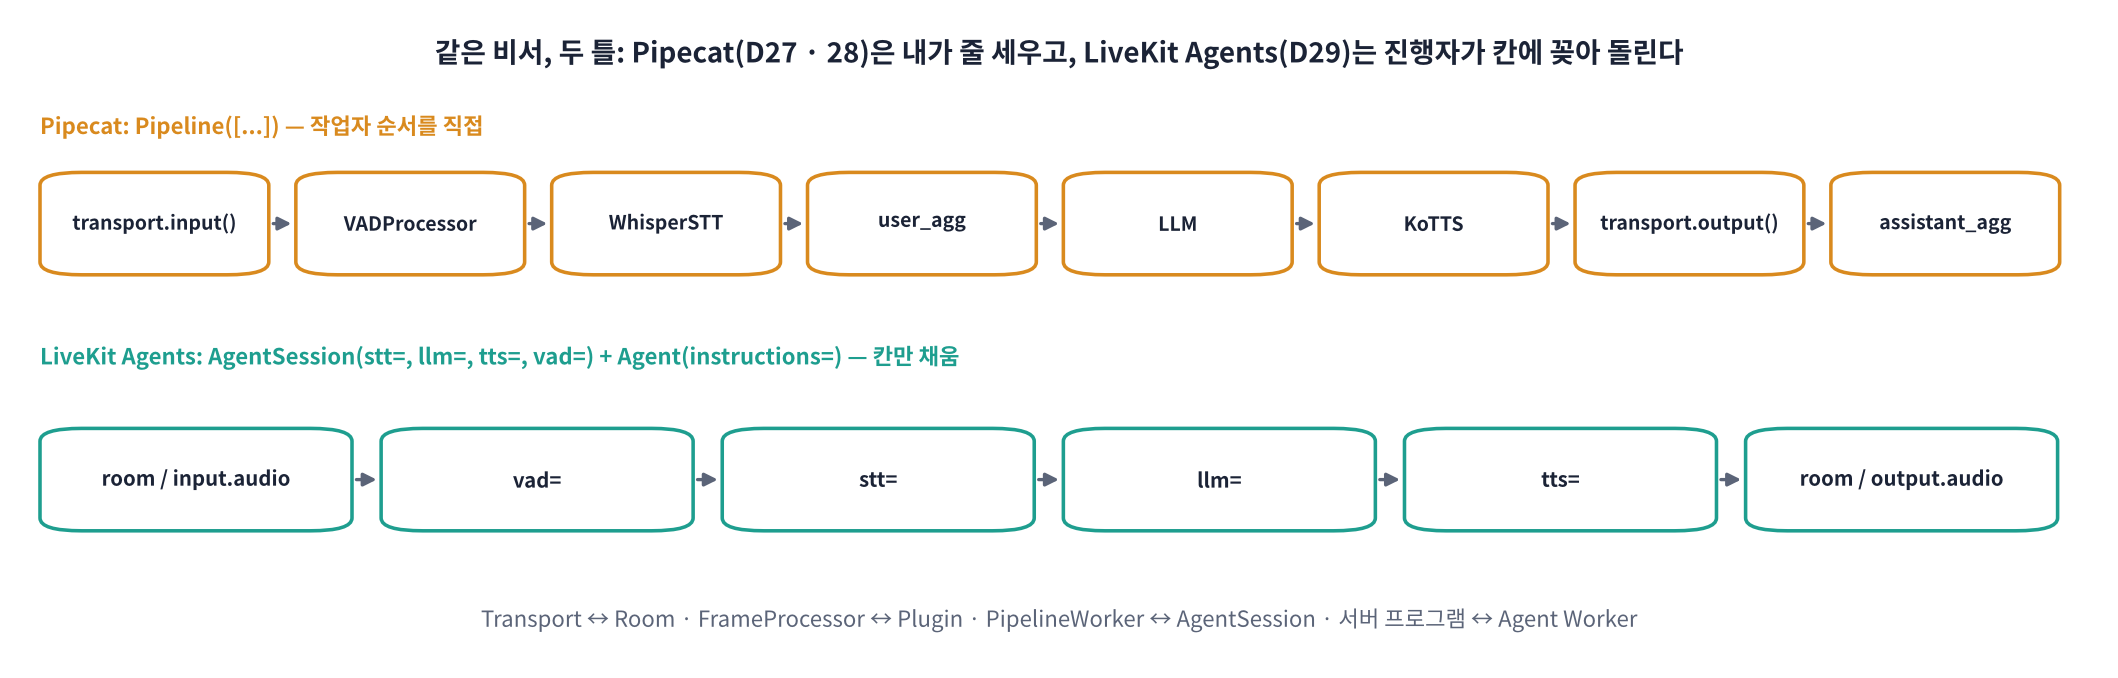

| 오늘 만든 것 | LiveKit 이름 | 한 줄 요약 |
|---|---|---|
| 출입증 | `api.AccessToken` · `VideoGrants` · `to_jwt()` | 서버만 가진 Secret으로 서명, 내용은 보이지만 고칠 수 없음 |
| 대본 | `Agent(instructions=...)` | 비서의 역할 · 지시문 |
| 진행자 | `AgentSession(stt, llm, tts, vad)` | 귀 · 머리 · 입을 엮고 턴을 판단, 메시지마다 `metrics` |
| 대본 리딩 | `session.run(user_input=...)` · `result.expect` | 소리 없이 글자로 시험 |
| 플러그인 | `_recognize_impl` · `LLMStream._run` · `ChunkedStream._run` | 정해진 부모 클래스 + 메서드 하나 |
| 입출력 자리 | `session.input.audio` · `session.output.audio` | 방 대신 가짜 마이크 · 스피커도 꽂힘 |
| 작업자 | `AgentServer` · `@server.rtc_session()` · `entrypoint(ctx)` | 방이 생기면 일감을 받아 세션을 방에 올림 |
| 연결 | `livekit-server --dev` · Python 참가자 · `jupyter.run_app` | 같은 entrypoint를 여러 무대에 |

### ✅ 오늘의 확인
- [ ] 사용자 · 비서 · 참관인 출입증의 권한 차이를 표로 설명할 수 있다.
- [ ] `session.run()`으로 3턴 대화를 시험하고, 턴별 TTFT를 읽었다.
- [ ] STT · TTS 플러그인을 단독으로 시험했고(`recognize` · `synthesize`), 세션에 꽂아 통화했다.
- [ ] fake job으로 작업자 · entrypoint를 시험했고, 진짜 방(또는 Cloud)에서 같은 entrypoint가 돌았다.

### 🔜 D30 예고: LiveKit 심화 & Speech-to-Speech
- **SIP**: 진짜 전화번호로 걸려 온 전화를 방에 연결하기
- **Multi-agent Handoff**: 예약 담당 Agent → 수납 담당 Agent로 넘기기 (세션은 그대로, 대본만 교체)
- **OpenAI Realtime · Gemini Live**: STT · LLM · TTS 세 칸을 **한 모델(Speech-to-Speech)** 로 바꾸면 무엇이 빨라지고 무엇을 잃는가

> 🎬 **애니메이션 D29-9:** [정리 퀴즈](https://imguru-mooc.github.io/AI_Voice/day29/animation.html#recap) — 상황별로 어느 LiveKit 부품을 고칠지 고르기

> ## 🎤 강사 스크립트 · Part 5 정리  ⏱️ 4분
>
> 🎯 **오늘 한 줄: 출입증으로 방에 들어가고, 대본 + 진행자로 비서를 만들고, 콘센트 모양만 맞춰 부품을 꽂고, 작업자가 방마다 entrypoint를 부른다.**
>
> 🖥️ [D29-9 정리 퀴즈](https://imguru-mooc.github.io/AI_Voice/day29/animation.html#recap)
>
> ➡️ "내일은 이 방에 **진짜 전화(SIP)** 를 연결하고, 대본을 통화 중에 바꾸고(Handoff), 귀 · 머리 · 입을 **한 모델(Realtime · Gemini Live)** 로 바꿔 봅니다. 오늘의 entrypoint가 그대로 출발점입니다."